In [ ]:
import pandas as pd
import numpy as np
import os

In [ ]:
# NEXUS | PHASE 01
# Dataset paths
DATA_PATH = "/content"

edges_path = os.path.join(DATA_PATH, "edges.csv")
hero_path = os.path.join(DATA_PATH, "hero-network.csv")
nodes_path = os.path.join(DATA_PATH, "nodes.csv")

# Loading datasets
edges = pd.read_csv(edges_path)
hero_network = pd.read_csv(hero_path)
nodes = pd.read_csv(nodes_path)

print("NEXUS DATASETS LOADED SUCCESSFULLY")
print("=" * 45)

print("Edges:", edges.shape)
print("Hero Network:", hero_network.shape)
print("Nodes:", nodes.shape)


NEXUS DATASETS LOADED SUCCESSFULLY
Edges: (96104, 2)
Hero Network: (574467, 2)
Nodes: (19090, 2)


In [ ]:
# Display first five records

print("\n========== EDGES ==========")
display(edges.head())

print("\n========== HERO NETWORK ==========")
display(hero_network.head())

print("\n========== NODES ==========")
display(nodes.head())



========== EDGES ==========


,hero,comic
0,24-HOUR MAN/EMMANUEL,AA2 35
1,3-D MAN/CHARLES CHAN,AVF 4
2,3-D MAN/CHARLES CHAN,AVF 5
3,3-D MAN/CHARLES CHAN,COC 1
4,3-D MAN/CHARLES CHAN,H2 251



========== HERO NETWORK ==========


,hero1,hero2
0,"LITTLE, ABNER",PRINCESS ZANDA
1,"LITTLE, ABNER",BLACK PANTHER/T'CHAL
2,BLACK PANTHER/T'CHAL,PRINCESS ZANDA
3,"LITTLE, ABNER",PRINCESS ZANDA
4,"LITTLE, ABNER",BLACK PANTHER/T'CHAL



========== NODES ==========


,node,type
0,2001 10,comic
1,2001 8,comic
2,2001 9,comic
3,24-HOUR MAN/EMMANUEL,hero
4,3-D MAN/CHARLES CHAN,hero


In [ ]:
datasets = {
    "edges": edges,
    "hero_network": hero_network,
    "nodes": nodes
}

for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    print("Columns:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())



DATASET: EDGES
Columns: ['hero', 'comic']

Data types:
hero     object
comic    object
dtype: object

Missing values:
hero     0
comic    0
dtype: int64

Duplicate rows: 0

DATASET: HERO_NETWORK
Columns: ['hero1', 'hero2']

Data types:
hero1    object
hero2    object
dtype: object

Missing values:
hero1    0
hero2    0
dtype: int64

Duplicate rows: 350286

DATASET: NODES
Columns: ['node', 'type']

Data types:
node    object
type    object
dtype: object

Missing values:
node    0
type    0
dtype: int64

Duplicate rows: 0


In [ ]:
#DATA CLEANING

# Removing duplicate relationships
hero_network_clean = hero_network.drop_duplicates().copy()

#  Removing self-connections, if any
hero_network_clean = hero_network_clean[
    hero_network_clean["hero1"] != hero_network_clean["hero2"]
].copy()

#  Checking node types
print("NODE TYPES:")
print(nodes["type"].value_counts())

#  Checking unique characters
characters = nodes[nodes["type"] == "hero"]["node"]
comics = nodes[nodes["type"] == "comic"]["node"]

print("\nUNIQUE CHARACTERS:", characters.nunique())
print("UNIQUE COMICS:", comics.nunique())

#  Checking network cleaning
print("\nORIGINAL HERO NETWORK:", len(hero_network))
print("CLEAN HERO NETWORK:", len(hero_network_clean))
print("DUPLICATES REMOVED:", len(hero_network) - len(hero_network_clean))

#  Verifying character-comic relationships
print("\nEDGES HERO COUNT:", edges["hero"].nunique())
print("EDGES COMIC COUNT:", edges["comic"].nunique())

print("\nDATA CLEANING COMPLETED.")


NODE TYPES:
type
comic    12651
hero      6439
Name: count, dtype: int64

UNIQUE CHARACTERS: 6439
UNIQUE COMICS: 12651

ORIGINAL HERO NETWORK: 574467
CLEAN HERO NETWORK: 224169
DUPLICATES REMOVED: 350298

EDGES HERO COUNT: 6439
EDGES COMIC COUNT: 12651

DATA CLEANING COMPLETED.


# Knowledge Graph Construction

In [ ]:

!pip -q install networkx

import networkx as nx

print("NetworkX version:", nx.__version__)


NetworkX version: 3.7


#

# CHARACTER KNOWLEDGE GRAPH

In [ ]:
G_characters = nx.Graph()

# Add all Marvel characters
for character in characters:
    G_characters.add_node(character, node_type="hero")

# Add character relationships
G_characters.add_edges_from(
    hero_network_clean[["hero1", "hero2"]].itertuples(
        index=False, name=None
    )
)

print("CHARACTER GRAPH CREATED")
print("Characters:", G_characters.number_of_nodes())
print("Connections:", G_characters.number_of_edges())
print("Isolated characters:", len(list(nx.isolates(G_characters))))


CHARACTER GRAPH CREATED
Characters: 6583
Connections: 167207
Isolated characters: 157


In [ ]:
G_characters = nx.Graph()

# Add all Marvel characters
for character in characters:
    G_characters.add_node(character, node_type="hero")

# Add character relationships
G_characters.add_edges_from(
    hero_network_clean[["hero1", "hero2"]].itertuples(
        index=False, name=None
    )
)

print("CHARACTER GRAPH CREATED")
print("Characters:", G_characters.number_of_nodes())
print("Connections:", G_characters.number_of_edges())
print("Isolated characters:", len(list(nx.isolates(G_characters))))


CHARACTER GRAPH CREATED
Characters: 6583
Connections: 167207
Isolated characters: 157


#  CHARACTER-COMIC GRAPH

In [ ]:
G_comics = nx.Graph()

# Add character nodes
for character in characters:
    G_comics.add_node(character, node_type="hero")

# Add comic nodes
for comic in comics:
    G_comics.add_node(comic, node_type="comic")

# Add character-comic connections
G_comics.add_edges_from(
    edges[["hero", "comic"]].itertuples(
        index=False, name=None
    )
)

print("CHARACTER-COMIC GRAPH CREATED")
print("Total nodes:", G_comics.number_of_nodes())
print("Total connections:", G_comics.number_of_edges())


CHARACTER-COMIC GRAPH CREATED
Total nodes: 19091
Total connections: 96104


In [ ]:
nx.write_graphml(G_characters, "/content/marvel_character_graph.graphml")
nx.write_graphml(G_comics, "/content/marvel_comic_graph.graphml")

print("NEXUS GRAPHS SAVED SUCCESSFULLY")


NEXUS GRAPHS SAVED SUCCESSFULLY


## Character Intelligence

In [ ]:
degree_data = dict(G_characters.degree())

degree_df = pd.DataFrame(
    degree_data.items(),
    columns=["character", "connections"]
)

degree_df = degree_df.sort_values(
    by="connections",
    ascending=False
).reset_index(drop=True)

print("TOP 20 MOST CONNECTED MARVEL CHARACTERS")
display(degree_df.head(20))


TOP 20 MOST CONNECTED MARVEL CHARACTERS


,character,connections
0,CAPTAIN AMERICA,1906
1,SPIDER-MAN/PETER PAR,1737
2,IRON MAN/TONY STARK,1522
3,THING/BENJAMIN J. GR,1416
4,MR. FANTASTIC/REED R,1379
5,WOLVERINE/LOGAN,1371
6,HUMAN TORCH/JOHNNY S,1361
7,SCARLET WITCH/WANDA,1325
8,THOR/DR. DONALD BLAK,1289
9,BEAST/HENRY &HANK& P,1267


#  CHARACTER COMIC APPEARANCES

In [ ]:
appearance_df = (
    edges.groupby("hero")["comic"]
    .nunique()
    .reset_index()
)

appearance_df.columns = [
    "character",
    "comic_appearances"
]

appearance_df = appearance_df.sort_values(
    "comic_appearances",
    ascending=False
).reset_index(drop=True)

print("TOP 20 CHARACTERS BY COMIC APPEARANCES")
display(appearance_df.head(20))


TOP 20 CHARACTERS BY COMIC APPEARANCES


,character,comic_appearances
0,SPIDER-MAN/PETER PARKER,1577
1,CAPTAIN AMERICA,1334
2,IRON MAN/TONY STARK,1150
3,THING/BENJAMIN J. GR,963
4,THOR/DR. DONALD BLAK,956
5,HUMAN TORCH/JOHNNY S,886
6,MR. FANTASTIC/REED R,854
7,HULK/DR. ROBERT BRUC,835
8,WOLVERINE/LOGAN,819
9,INVISIBLE WOMAN/SUE,762


# CHARACTER INFLUENCE

In [ ]:
pagerank_scores = nx.pagerank(
    G_characters,
    alpha=0.85
)

influence_df = pd.DataFrame(
    pagerank_scores.items(),
    columns=["character", "pagerank"]
)

influence_df = influence_df.sort_values(
    "pagerank",
    ascending=False
).reset_index(drop=True)

print("TOP 20 CHARACTERS BY PAGERANK")
display(influence_df.head(20))


TOP 20 CHARACTERS BY PAGERANK


,character,pagerank
0,SPIDER-MAN/PETER PAR,0.005304
1,CAPTAIN AMERICA,0.005098
2,IRON MAN/TONY STARK,0.004094
3,WOLVERINE/LOGAN,0.003856
4,THING/BENJAMIN J. GR,0.003660
5,MR. FANTASTIC/REED R,0.003558
6,HUMAN TORCH/JOHNNY S,0.003487
7,SCARLET WITCH/WANDA,0.003201
8,THOR/DR. DONALD BLAK,0.003188
9,BEAST/HENRY &HANK& P,0.003173


# CHARACTER INTELLIGENCE DATABASE

In [ ]:
character_intelligence = (
    degree_df
    .merge(appearance_df, on="character", how="outer")
    .merge(influence_df, on="character", how="outer")
)

character_intelligence = character_intelligence.fillna(0)

character_intelligence.to_csv(
    "/content/nexus_character_intelligence.csv",
    index=False
)

print("CHARACTER INTELLIGENCE DATABASE CREATED")
print(character_intelligence.shape)


CHARACTER INTELLIGENCE DATABASE CREATED
(6584, 4)


## Community Detection

In [ ]:
import networkx as nx
import community as community_louvain

# Creating a working copy
G_community = G_characters.copy()

# Assigning equal weight to every relationship
nx.set_edge_attributes(
    G_community,
    1,
    "weight"
)

# Detect communities
partition = community_louvain.best_partition(
    G_community,
    weight="weight",
    random_state=42
)

# Adding community IDs to character intelligence
character_intelligence["community"] = (
    character_intelligence["character"].map(partition)
)

# Community statistics
community_sizes = (
    pd.Series(partition)
    .value_counts()
    .sort_values(ascending=False)
)

print("COMMUNITY DETECTION SUCCESSFUL")
print("Total communities:", len(community_sizes))
print("\nLargest 15 communities:")
print(community_sizes.head(15))



COMMUNITY DETECTION SUCCESSFUL
Total communities: 182

Largest 15 communities:
5     1374
13    1070
4     1027
1      876
3      459
2      368
24     239
15     220
9      210
16     148
6      118
8      105
7       50
0       33
30      31
Name: count, dtype: int64


In [ ]:
# Saving updated intelligence
character_intelligence.to_csv(
    "/content/nexus_character_intelligence.csv",
    index=False
)

pd.DataFrame(
    partition.items(),
    columns=["character", "community"]
).to_csv(
    "/content/nexus_communities.csv",
    index=False
)

print("NEXUS COMMUNITY DATA SAVED")


NEXUS COMMUNITY DATA SAVED


# Character Intelligence Profiles

In [ ]:
def get_character_profile(character_name):

    matches = [
        name for name in G_characters.nodes
        if character_name.lower() in name.lower()
    ]

    if not matches:
        print("Character not found.")
        return

    for character in matches[:5]:

        connections = list(G_characters.neighbors(character))

        appearances = (
            edges.loc[
                edges["hero"] == character,
                "comic"
            ].unique().tolist()
        )

        info = character_intelligence[
            character_intelligence["character"] == character
        ]

        print("\n" + "=" * 45)
        print("CHARACTER:", character)
        print("=" * 45)

        if not info.empty:
            print("Connections:", int(info.iloc[0]["connections"]))
            print("Comic appearances:", int(info.iloc[0]["comic_appearances"]))
            print("PageRank:", round(info.iloc[0]["pagerank"], 6))
            print("Community:", info.iloc[0]["community"])

        print("\nCONNECTED CHARACTERS:")
        print(connections[:20])

        print("\nCOMIC APPEARANCES:")
        print("Total:", len(appearances))
        print("Examples:", appearances[:20])



In [ ]:

get_character_profile("IRON MAN")



CHARACTER: IRON MAN ARMOR
Connections: 6
Comic appearances: 3
PageRank: 3.7e-05
Community: 13.0

CONNECTED CHARACTERS:
['IRON MAN/TONY STARK ', 'FUJIKAWA, RUMIKO', 'HOGAN, VIRGINIA PEPP', 'WHIPLASH/MARK SCARLO', 'JOCASTA', 'HOGAN, HAROLD J. HAP']

COMIC APPEARANCES:
Total: 3
Examples: ['IM3 26', 'IM3 27', 'IM3 28']

CHARACTER: IRON MAN DOPPELGANGE
Connections: 141
Comic appearances: 7
PageRank: 0.000308
Community: 3.0

CONNECTED CHARACTERS:
['THING DOPPELGANGER', 'WOLVERINE DOPPELGANG', 'WONDER MAN/SIMON WIL', 'HERCULES DOPPELGANGE', 'DR. STRANGE/STEPHEN ', 'NAMORITA/NITA PRENTI', 'SERSI/SYLVIA', 'GALACTUS/GALAN', 'COLOSSUS II DOPPELGA', 'PIP/PRINCE GOFERN', 'DAREDEVIL DOPPELGANG', 'NOVA II/FRANKIE RAYE', 'CAPTAIN AMERICA', 'MR. FANTASTIC DOPPEL', 'PSYLOCKE/ELISABETH B', 'BLACK WIDOW/NATASHA ', 'HAVOK/ALEX SUMMERS ', 'SCARLET WITCH/WANDA ', 'SPEEDBALL DOPPELGANG', 'SPIDER-MAN/PETER PAR']

COMIC APPEARANCES:
Total: 7
Examples: ['FF 367', 'FF 368', 'IW 1', 'IW 2', 'IW 3', 'MK3 41', 'WM2

In [ ]:

get_character_profile("SPIDER-MAN")
get_character_profile("CAPTAIN AMERICA")
get_character_profile("THOR")



CHARACTER: SPIDER-MAN CLONE/BEN
Connections: 355
Comic appearances: 167
PageRank: 0.001146
Community: 4.0

CONNECTED CHARACTERS:
['KAINE', 'GREGOR', 'RAVEN, LT. JACOB', 'TREVANE, DET. CONNOR', 'GRIM HUNTER/KRAVINOF', 'SPIDER-MAN/PETER PAR', 'PARKER, MAY', 'TOMBSTONE/LONNIE THO', 'BYRNES, GAYLE WATSON', 'LEEDS, BETTY BRANT', 'WATSON-PARKER, MARY ', 'ELLIS, KEN', 'THOMPSON, EUGENE FLA', 'CAPUTO, DR. JULIA', 'JACK', 'JACKAL/MILES WARREN', 'SPIDERCIDE', 'WATSON, ANNA', 'GUARDIAN IV', 'ROBERTSON, JOE']

COMIC APPEARANCES:
Total: 167
Examples: ['A 400', 'ASM 149', 'ASM 151', 'ASM 393', 'ASM 394', 'ASM 394/2', 'ASM 399', 'ASM 400', 'ASM 400/3', 'ASM 401', 'ASM 403', 'ASM 404', 'ASM 405', 'ASM 406', 'ASM 407', 'ASM 408', 'ASM 409', 'ASM 410', 'ASM 411', 'ASM 412']

CHARACTER: SPIDER-MAN III/MARTH
Connections: 64
Comic appearances: 27
PageRank: 0.000261
Community: 4.0

CONNECTED CHARACTERS:
['JAMESON, J. JONAH', 'ROBERTSON, JOE', 'RANGER I/', 'LEEDS, BETTY BRANT', 'WARD, SEN. STEWART', 'STACY,

In [ ]:
character_intelligence.to_csv(
    "/content/nexus_character_intelligence.csv",
    index=False
)

print("NEXUS CHARACTER PROFILES READY")


NEXUS CHARACTER PROFILES READY


# Data consistency correction

In [ ]:

# ==========================================
# NEXUS | NAME NORMALISATION
# ==========================================

def clean_name(value):
    return str(value).strip()

# Clean original datasets
edges["hero"] = edges["hero"].apply(clean_name)
edges["comic"] = edges["comic"].apply(clean_name)

hero_network_clean["hero1"] = (
    hero_network_clean["hero1"].apply(clean_name)
)

hero_network_clean["hero2"] = (
    hero_network_clean["hero2"].apply(clean_name)
)

nodes["node"] = nodes["node"].apply(clean_name)

# Remove duplicate edges after normalisation
hero_network_clean = hero_network_clean.drop_duplicates()

print("NAME NORMALISATION COMPLETED")


NAME NORMALISATION COMPLETED


In [ ]:

G_characters = nx.Graph()

G_characters.add_nodes_from(
    nodes.loc[nodes["type"] == "hero", "node"]
)

G_characters.add_edges_from(
    hero_network_clean[["hero1", "hero2"]].itertuples(
        index=False, name=None
    )
)

print("Nodes:", G_characters.number_of_nodes())
print("Edges:", G_characters.number_of_edges())


Nodes: 6442
Edges: 167100


In [ ]:

def get_character_profile(character_name):

    matches = [
        name for name in G_characters.nodes
        if character_name.lower() in name.lower()
    ]

    if not matches:
        print("Character not found.")
        return

    for character in matches[:5]:

        connections = list(G_characters.neighbors(character))

        appearances = edges.loc[
            edges["hero"] == character,
            "comic"
        ].unique().tolist()

        info = character_intelligence[
            character_intelligence["character"] == character
        ]

        print("\n" + "=" * 45)
        print("CHARACTER:", character)
        print("=" * 45)

        print("Connections:", len(connections))
        print("Comic appearances:", len(appearances))

        if not info.empty:
            print("PageRank:", info.iloc[0]["pagerank"])
            print("Community:", info.iloc[0]["community"])

        print("\nCONNECTED CHARACTERS:")
        print(connections[:15])

        print("\nCOMIC EXAMPLES:")
        print(appearances[:15])


In [ ]:

get_character_profile("IRON MAN/TONY STARK")
get_character_profile("SPIDER-MAN/PETER PAR")



CHARACTER: IRON MAN/TONY STARK
Connections: 1521
Comic appearances: 1150
PageRank: 2.3257436565522767e-05
Community: 92.0

CONNECTED CHARACTERS:
['STEELE, SIMON/WOLFGA', 'RAVEN, SABBATH II/EL', 'IRON MAN IV/JAMES R.', 'FORTUNE, DOMINIC', 'ERWIN, CLYTEMNESTRA', 'GHOST', 'ZIMMER, ABE', 'TIGRA/GREER NELSON', 'QUICKSILVER/PIETRO M', 'WASP/JANET VAN DYNE', 'GALACTUS/GALAN', 'MOCKINGBIRD/DR. BARB', 'SILVER SURFER/NORRIN', 'HAWK', 'LORD CHAOS']

COMIC EXAMPLES:
["A '00", 'A 1', 'A 10', 'A 100', 'A 101', 'A 102', 'A 103', 'A 104', 'A 105', 'A 106', 'A 107', 'A 108', 'A 109', 'A 11', 'A 110']

CHARACTER: SPIDER-MAN/PETER PARKERKER
Connections: 0
Comic appearances: 0
PageRank: 2.3257436565522767e-05
Community: 162.0

CONNECTED CHARACTERS:
[]

COMIC EXAMPLES:
[]

CHARACTER: SPIDER-MAN/PETER PAR
Connections: 1737
Comic appearances: 0
PageRank: 0.005303689099941489
Community: 4.0

CONNECTED CHARACTERS:
['NOVA/RICHARD RIDER', 'FIRESTAR/ANGELICA JO', 'THUNDERBALL/DR. ELIO', 'NAMORITA/NITA PRENTI', '

In [ ]:
print("SPIDER-MAN names in nodes:")
print(nodes[nodes["node"].str.contains("SPIDER-MAN", case=False, na=False)]["node"].unique())

print("\nSPIDER-MAN names in edges:")
print(edges[edges["hero"].str.contains("SPIDER-MAN", case=False, na=False)]["hero"].unique())

SPIDER-MAN names in nodes:
['SPIDER-MAN CLONE/BEN' 'SPIDER-MAN: FEAR ITS' 'SPIDER-MAN III/MARTH'
 'SPIDER-MAN/PETER PARKERKER']

SPIDER-MAN names in edges:
['SPIDER-MAN CLONE/BEN' 'SPIDER-MAN III/MARTH' 'SPIDER-MAN/PETER PARKER']


In [ ]:
# Correct the inconsistent Spider-Man name
nodes["node"] = nodes["node"].replace(
    "SPIDER-MAN/PETER PARKERKER",
    "SPIDER-MAN/PETER PARKER"
)

# Rebuild character graph
G_characters = nx.Graph()

G_characters.add_nodes_from(
    nodes.loc[nodes["type"] == "hero", "node"]
)

G_characters.add_edges_from(
    hero_network_clean[["hero1", "hero2"]].itertuples(
        index=False, name=None
    )
)

# Verify Spider-Man
get_character_profile("SPIDER-MAN/PETER PARKER")


CHARACTER: SPIDER-MAN/PETER PARKER
Connections: 0
Comic appearances: 1577
PageRank: 0.0
Community: nan

CONNECTED CHARACTERS:
[]

COMIC EXAMPLES:
['A 11', 'A 118', 'A 1.5', 'A 168', 'A 221', 'A 235', 'A 236', 'A 237', 'A 258', 'A 298', 'A 3', 'A3 1', 'A3 10', 'A3 11', 'A 314']


In [ ]:
# Standardise Spider-Man's name in the relationship dataset
hero_network_clean[["hero1", "hero2"]] = (
    hero_network_clean[["hero1", "hero2"]].replace(
        "SPIDER-MAN/PETER PAR",
        "SPIDER-MAN/PETER PARKER"
    )
)

# Rebuild character graph
G_characters = nx.Graph()

G_characters.add_nodes_from(
    nodes.loc[nodes["type"] == "hero", "node"]
)

G_characters.add_edges_from(
    hero_network_clean[["hero1", "hero2"]].itertuples(
        index=False, name=None
    )
)

get_character_profile("SPIDER-MAN/PETER PARKER")


CHARACTER: SPIDER-MAN/PETER PARKER
Connections: 1737
Comic appearances: 1577
PageRank: 0.0
Community: nan

CONNECTED CHARACTERS:
['NOVA/RICHARD RIDER', 'FIRESTAR/ANGELICA JO', 'THUNDERBALL/DR. ELIO', 'NAMORITA/NITA PRENTI', 'SPEEDBALL/ROBBIE BAL', 'HULK/DR. ROBERT BRUC', 'NIGHT THRASHER/DUANE', 'STACY, PAUL', 'STACY, JILL', 'STACY, ARTHUR', 'PARKER, MAY', 'VENOM/EDDIE BROCK', 'BLADE', 'KINGPIN/WILSON FISK', 'LEEDS, BETTY BRANT']

COMIC EXAMPLES:
['A 11', 'A 118', 'A 1.5', 'A 168', 'A 221', 'A 235', 'A 236', 'A 237', 'A 258', 'A 298', 'A 3', 'A3 1', 'A3 10', 'A3 11', 'A 314']


In [ ]:
degree_df = pd.DataFrame(
    G_characters.degree(),
    columns=["character", "connections"]
)

pagerank_df = pd.DataFrame(
    nx.pagerank(G_characters).items(),
    columns=["character", "pagerank"]
)

appearance_df = (
    edges.groupby("hero")["comic"]
    .nunique()
    .reset_index()
    .rename(columns={"hero": "character",
                     "comic": "comic_appearances"})
)

character_intelligence = (
    degree_df
    .merge(appearance_df, on="character", how="left")
    .merge(pagerank_df, on="character", how="left")
)

character_intelligence = character_intelligence.fillna(0)

G_community = G_characters.copy()
nx.set_edge_attributes(G_community, 1, "weight")

partition = community_louvain.best_partition(
    G_community, weight="weight", random_state=42
)

character_intelligence["community"] = (
    character_intelligence["character"].map(partition)
)

character_intelligence.to_csv(
    "/content/nexus_character_intelligence.csv",
    index=False
)

print("Shape:", character_intelligence.shape)
print(character_intelligence.nlargest(10, "connections"))

Shape: (6441, 5)
                    character  connections  comic_appearances  pagerank  \
857           CAPTAIN AMERICA         1903             1334.0  0.005112   
5299  SPIDER-MAN/PETER PARKER         1737             1577.0  0.005324   
2654      IRON MAN/TONY STARK         1521             1150.0  0.004108   
5703     THING/BENJAMIN J. GR         1416              963.0  0.003674   
3797     MR. FANTASTIC/REED R         1377              854.0  0.003568   
6294          WOLVERINE/LOGAN         1368              819.0  0.003865   
2547     HUMAN TORCH/JOHNNY S         1361              886.0  0.003500   
4886      SCARLET WITCH/WANDA         1322              643.0  0.003207   
5722     THOR/DR. DONALD BLAK         1289              956.0  0.003201   
405      BEAST/HENRY &HANK& P         1265              635.0  0.003181   

      community  
857           4  
5299          7  
2654          4  
5703         17  
3797         17  
6294          5  
2547         17  
4886         

In [ ]:
edges.to_csv("/content/nexus_edges_clean.csv", index=False)
hero_network_clean.to_csv("/content/nexus_relationships_clean.csv", index=False)
nodes.to_csv("/content/nexus_nodes_clean.csv", index=False)

nx.write_graphml(
    G_characters,
    "/content/nexus_character_graph.graphml"
)

print("NEXUS datasets and graph saved successfully.")

NEXUS datasets and graph saved successfully.


# NLP & Named Entity Recognition (NER).

In [ ]:
!pip -q install spacy sentence-transformers faiss-cpu
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 97.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("NEXUS NLP engine loaded:", nlp.meta["name"])

NEXUS NLP engine loaded: core_web_sm


In [ ]:
sample_text = """
Tony Stark is Iron Man. He works with Captain America.
Peter Parker is Spider-Man. Thor and Loki are connected
to Asgard. Bruce Banner transforms into the Hulk.
"""

doc = nlp(sample_text)

for ent in doc.ents:
    print(ent.text, "->", ent.label_)

Tony Stark -> PERSON
Captain America -> LOC
Peter Parker -> PERSON
Spider-Man -> PERSON
Loki -> PERSON
Bruce Banner -> PERSON
Hulk -> ORG


In [ ]:
# Marvel character dictionary
marvel_characters = {
    "Tony Stark": "IRON MAN/TONY STARK",
    "Iron Man": "IRON MAN/TONY STARK",
    "Captain America": "CAPTAIN AMERICA",
    "Steve Rogers": "CAPTAIN AMERICA",
    "Peter Parker": "SPIDER-MAN/PETER PARKER",
    "Spider-Man": "SPIDER-MAN/PETER PARKER",
    "Bruce Banner": "HULK/DR. ROBERT BRUCE",
    "Hulk": "HULK/DR. ROBERT BRUCE",
    "Thor": "THOR/DR. DONALD BLAK",
    "Loki": "LOKI",
    "Wanda": "SCARLET WITCH/WANDA",
    "Scarlet Witch": "SCARLET WITCH/WANDA"
}

def nexus_entity_recognition(text):
    doc = nlp(text)
    found = []

    for alias, canonical_name in marvel_characters.items():
        if alias.lower() in text.lower():
            found.append({
                "mentioned_as": alias,
                "canonical_character": canonical_name
            })

    return pd.DataFrame(found).drop_duplicates()

entities = nexus_entity_recognition(sample_text)
display(entities)

,mentioned_as,canonical_character
0,Tony Stark,IRON MAN/TONY STARK
1,Iron Man,IRON MAN/TONY STARK
2,Captain America,CAPTAIN AMERICA
3,Peter Parker,SPIDER-MAN/PETER PARKER
4,Spider-Man,SPIDER-MAN/PETER PARKER
5,Bruce Banner,HULK/DR. ROBERT BRUCE
6,Hulk,HULK/DR. ROBERT BRUCE
7,Thor,THOR/DR. DONALD BLAK
8,Loki,LOKI


In [ ]:
from itertools import combinations
from collections import Counter

def nexus_relationship_extraction(text):
    entities = nexus_entity_recognition(text)

    characters_found = sorted(
        set(entities["canonical_character"])
    )

    relationships = []

    for char1, char2 in combinations(characters_found, 2):
        relationships.append({
            "character_1": char1,
            "character_2": char2,
            "relationship_type": "co_mentioned",
            "evidence": text
        })

    return pd.DataFrame(relationships)

relationships = nexus_relationship_extraction(sample_text)
display(relationships)

,character_1,character_2,relationship_type,evidence
0,CAPTAIN AMERICA,HULK/DR. ROBERT BRUCE,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
1,CAPTAIN AMERICA,IRON MAN/TONY STARK,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
2,CAPTAIN AMERICA,LOKI,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
3,CAPTAIN AMERICA,SPIDER-MAN/PETER PARKER,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
4,CAPTAIN AMERICA,THOR/DR. DONALD BLAK,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
5,HULK/DR. ROBERT BRUCE,IRON MAN/TONY STARK,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
6,HULK/DR. ROBERT BRUCE,LOKI,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
7,HULK/DR. ROBERT BRUCE,SPIDER-MAN/PETER PARKER,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
8,HULK/DR. ROBERT BRUCE,THOR/DR. DONALD BLAK,co_mentioned,\nTony Stark is Iron Man. He works with Captai...
9,IRON MAN/TONY STARK,LOKI,co_mentioned,\nTony Stark is Iron Man. He works with Captai...


In [ ]:
# Save extracted relationships
relationships.to_csv(
    "/content/nexus_narrative_relationships.csv",
    index=False
)

# Add extracted pairs to a separate graph
G_narrative = nx.Graph()

for _, row in relationships.iterrows():
    G_narrative.add_edge(
        row["character_1"],
        row["character_2"],
        relationship_type=row["relationship_type"],
        evidence=row["evidence"]
    )

print("Narrative graph nodes:", G_narrative.number_of_nodes())
print("Narrative graph edges:", G_narrative.number_of_edges())

Narrative graph nodes: 6
Narrative graph edges: 15


In [ ]:
character = "IRON MAN/TONY STARK"

print("Existing network connections:",
      G_characters.degree(character))

print("Narrative co-mentions:",
      G_narrative.degree(character))

Existing network connections: 1521
Narrative co-mentions: 5


# : NEXUS event extraction

In [ ]:
import re

action_verbs = [
    "fights", "fought", "helps", "helped",
    "joins", "joined", "defeats", "defeated",
    "meets", "met", "attacks", "attacked",
    "saves", "saved", "works with",
    "transforms into", "protects", "protected"
]

def nexus_event_extraction(text):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    events = []

    for sentence in sentences:
        for verb in action_verbs:
            if re.search(r'\b' + re.escape(verb) + r'\b',
                         sentence, re.IGNORECASE):
                events.append({
                    "sentence": sentence,
                    "action": verb
                })

    return pd.DataFrame(events)

events = nexus_event_extraction(sample_text)
display(events)

,sentence,action
0,He works with Captain America.,works with
1,Bruce Banner transforms into the Hulk.,transforms into


In [ ]:
def nexus_event_participants(text):
    events = nexus_event_extraction(text)
    results = []

    for _, event in events.iterrows():
        sentence = event["sentence"]
        entities = nexus_entity_recognition(sentence)

        participants = list(
            entities["canonical_character"].unique()
        )

        results.append({
            "event": event["action"],
            "participants": participants,
            "source_sentence": sentence
        })

    return pd.DataFrame(results)

event_data = nexus_event_participants(sample_text)
display(event_data)

,event,participants,source_sentence
0,works with,[CAPTAIN AMERICA],He works with Captain America.
1,transforms into,[HULK/DR. ROBERT BRUCE],Bruce Banner transforms into the Hulk.


In [ ]:
G_nexus = nx.Graph()

# Add character nodes
for character in marvel_characters.values():
    G_nexus.add_node(character, node_type="character")

# Add co-mention relationships
for _, row in relationships.iterrows():
    G_nexus.add_edge(
        row["character_1"],
        row["character_2"],
        relation="co_mentioned"
    )

# Add event nodes and participant links
for i, row in event_data.iterrows():
    event_id = f"EVENT_{i}"

    G_nexus.add_node(
        event_id,
        node_type="event",
        action=row["event"],
        source=row["source_sentence"]
    )

    for participant in row["participants"]:
        G_nexus.add_edge(
            participant,
            event_id,
            relation="participated_in"
        )

print("NEXUS unified graph")
print("Nodes:", G_nexus.number_of_nodes())
print("Edges:", G_nexus.number_of_edges())

NEXUS unified graph
Nodes: 9
Edges: 17


In [ ]:
nx.write_graphml(G_nexus, "/content/nexus_unified_graph.graphml")

In [ ]:
from sentence_transformers import SentenceTransformer
import faiss
import numpy as np

# Free, open-source embedding model
embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

# Prepare character documents
character_docs = []

for _, row in character_intelligence.iterrows():
    character_docs.append(
        f"{row['character']}. "
        f"Connections: {row['connections']}. "
        f"Comic appearances: {row['comic_appearances']}."
    )

# Generate embeddings
embeddings = embedding_model.encode(
    character_docs,
    convert_to_numpy=True,
    show_progress_bar=True
)

embeddings = embeddings.astype("float32")

print("Embedding shape:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/202 [00:00<?, ?it/s]

Embedding shape: (6441, 384)


In [ ]:
dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(dimension)

# Normalise for cosine similarity
faiss.normalize_L2(embeddings)

faiss_index.add(embeddings)

print("FAISS vectors:", faiss_index.ntotal)

FAISS vectors: 6441


In [ ]:
def nexus_search(query, top_k=5):
    query_vector = embedding_model.encode(
        [query], convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_vector)

    scores, indices = faiss_index.search(
        query_vector, top_k
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx == -1:
            continue

        results.append({
            "character": character_intelligence.iloc[idx]["character"],
            "similarity": round(float(score), 4),
            "connections": int(character_intelligence.iloc[idx]["connections"]),
            "comic_appearances": int(character_intelligence.iloc[idx]["comic_appearances"])
        })

    return pd.DataFrame(results)

In [ ]:
display(nexus_search("Which superheroes have many connections?"))

,character,similarity,connections,comic_appearances
0,NOBLE,0.6145,5,1
1,ANIMUS,0.5837,3,1
2,DR. POWER/DR. MAXIMU,0.5808,4,1
3,MARVEL BOY VII/DAVID,0.5783,4,1
4,SUPER-PATRIOT,0.5746,5,1


In [ ]:
display(nexus_search("Characters who appear in many comics"))

,character,similarity,connections,comic_appearances
0,KEEPER OF THE COMICS,0.5939,9,2
1,NEOPHYTE/,0.5894,55,5
2,WARRIOR WOMAN/JULIA,0.5750,46,12
3,CHAR,0.5727,21,3
4,FACE/COL. EISEN,0.5719,7,1


In [ ]:
character_docs = []

for _, row in character_intelligence.iterrows():
    character_docs.append(
        f"""
        Marvel character: {row['character']}.
        Network connections: {row['connections']}.
        Comic appearances: {row['comic_appearances']}.
        Network importance score: {row['pagerank']}.
        Community: {row['community']}.
        """
    )

# Regenerate embeddings
embeddings = embedding_model.encode(
    character_docs,
    convert_to_numpy=True,
    show_progress_bar=True
).astype("float32")

faiss.normalize_L2(embeddings)

# Rebuild FAISS
faiss_index = faiss.IndexFlatIP(embeddings.shape[1])
faiss_index.add(embeddings)

print("Updated FAISS index:", faiss_index.ntotal)

Batches:   0%|          | 0/202 [00:00<?, ?it/s]

Updated FAISS index: 6441


In [ ]:
display(nexus_search("Which characters are highly connected?"))

,character,similarity,connections,comic_appearances
0,"STRONG, SUSAN",0.5681,16,3
1,"DRAGONBLOOD, ULYSSES",0.5507,37,6
2,NOBLE,0.5490,5,1
3,BLOODSTONE/ULYSSES B,0.5477,43,18
4,CHAR,0.5455,21,3


# Building graph retrieval

In [ ]:
def nexus_graph_search(query, top_k=5):
    query_lower = query.lower()

    if "connected" in query_lower or "connections" in query_lower:
        results = character_intelligence.sort_values(
            "connections", ascending=False
        )

    elif "comic" in query_lower or "appearances" in query_lower:
        results = character_intelligence.sort_values(
            "comic_appearances", ascending=False
        )

    elif "influential" in query_lower or "important" in query_lower:
        results = character_intelligence.sort_values(
            "pagerank", ascending=False
        )

    else:
        results = character_intelligence.sort_values(
            "connections", ascending=False
        )

    return results[
        ["character", "connections", "comic_appearances",
         "pagerank", "community"]
    ].head(top_k).reset_index(drop=True)

In [ ]:
display(nexus_graph_search("Which characters are highly connected?"))

,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THING/BENJAMIN J. GR,1416,963.0,0.003674,17
4,MR. FANTASTIC/REED R,1377,854.0,0.003568,17


In [ ]:
def nexus_hybrid_search(query, top_k=5):
    semantic = nexus_search(query, top_k=20)

    graph = nexus_graph_search(query, top_k=20)

    semantic["semantic_score"] = semantic["similarity"]

    graph["graph_score"] = (
        graph["pagerank"] / graph["pagerank"].max()
    )

    combined = semantic.merge(
        graph[["character", "graph_score"]],
        on="character",
        how="outer"
    ).fillna(0)

    combined["hybrid_score"] = (
        0.5 * combined["semantic_score"] +
        0.5 * combined["graph_score"]
    )

    return combined.sort_values(
        "hybrid_score", ascending=False
    ).head(top_k).reset_index(drop=True)

In [ ]:
display(
    nexus_hybrid_search(
        "Which Marvel characters are highly connected?"
    )
)

,character,similarity,connections,comic_appearances,semantic_score,graph_score,hybrid_score
0,SPIDER-MAN/PETER PARKER,0.0,0.0,0.0,0.0,1.000000,0.500000
1,CAPTAIN AMERICA,0.0,0.0,0.0,0.0,0.960121,0.480060
2,IRON MAN/TONY STARK,0.0,0.0,0.0,0.0,0.771598,0.385799
3,WOLVERINE/LOGAN,0.0,0.0,0.0,0.0,0.725990,0.362995
4,THING/BENJAMIN J. GR,0.0,0.0,0.0,0.0,0.690122,0.345061


In [ ]:
def nexus_hybrid_search(query, top_k=5):

    query_lower = query.lower()

    # Use actual graph metrics for graph-specific questions
    if any(word in query_lower for word in
           ["connected", "connections", "influential",
            "important", "appearances"]):

        if "appearance" in query_lower or "comic" in query_lower:
            sort_column = "comic_appearances"
        elif "influential" in query_lower or "important" in query_lower:
            sort_column = "pagerank"
        else:
            sort_column = "connections"

        return (
            character_intelligence
            .sort_values(sort_column, ascending=False)
            [["character", "connections",
              "comic_appearances", "pagerank", "community"]]
            .head(top_k)
            .reset_index(drop=True)
        )

    # Otherwise use semantic retrieval
    return nexus_search(query, top_k)


# Test
nexus_hybrid_search("Which Marvel characters are highly connected?")

,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THING/BENJAMIN J. GR,1416,963.0,0.003674,17
4,MR. FANTASTIC/REED R,1377,854.0,0.003568,17


In [ ]:
display(
    nexus_hybrid_search(
        "Which Marvel characters are highly connected?"
    )
)

,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THING/BENJAMIN J. GR,1416,963.0,0.003674,17
4,MR. FANTASTIC/REED R,1377,854.0,0.003568,17


In [ ]:
def nexus_character_profile(name):

    matches = character_intelligence[
        character_intelligence["character"].str.contains(
            name, case=False, na=False
        )
    ]

    if matches.empty:
        return "Character not found."

    return matches.sort_values(
        "connections", ascending=False
    ).iloc[0]


# Test
nexus_character_profile("IRON MAN")

,2654
character,IRON MAN/TONY STARK
connections,1521
comic_appearances,1150.0
pagerank,0.004108
community,4


In [ ]:
def nexus_compare(char1, char2):

    profile1 = nexus_character_profile(char1)
    profile2 = nexus_character_profile(char2)

    if isinstance(profile1, str) or isinstance(profile2, str):
        return "One or both characters were not found."

    comparison = pd.DataFrame({
        "Metric": [
            "Connections",
            "Comic appearances",
            "PageRank"
        ],
        char1: [
            profile1["connections"],
            profile1["comic_appearances"],
            profile1["pagerank"]
        ],
        char2: [
            profile2["connections"],
            profile2["comic_appearances"],
            profile2["pagerank"]
        ]
    })

    return comparison


# Test
nexus_compare("IRON MAN", "SPIDER-MAN")

,Metric,IRON MAN,SPIDER-MAN
0,Connections,1521.000000,1737.000000
1,Comic appearances,1150.000000,1577.000000
2,PageRank,0.004108,0.005324


## Building a team/community intelligence function

In [ ]:
def nexus_community_search(character_name):

    profile = nexus_character_profile(character_name)

    if isinstance(profile, str):
        return profile

    community_id = profile["community"]

    members = character_intelligence[
        character_intelligence["community"] == community_id
    ].copy()

    return members.sort_values(
        "connections", ascending=False
    )[[
        "character",
        "connections",
        "comic_appearances",
        "pagerank"
    ]].head(15).reset_index(drop=True)


# Test
nexus_community_search("IRON MAN")

,character,connections,comic_appearances,pagerank
0,CAPTAIN AMERICA,1903,1334.0,0.005112
1,IRON MAN/TONY STARK,1521,1150.0,0.004108
2,HAWK,1175,605.0,0.003059
3,ANT-MAN/DR. HENRY J.,1082,561.0,0.002650
4,"JARVIS, EDWIN",986,399.0,0.002404
5,"FURY, COL. NICHOLAS",922,471.0,0.002608
6,FALCON/SAM WILSON,541,221.0,0.001279
7,BINARY/CAROL DANVERS,537,172.0,0.001275
8,"DUGAN, TIMOTHY ALOYI",497,227.0,0.001422
9,IRON MAN IV/JAMES R.,465,250.0,0.001308


## Character recommendations based on network connections

In [ ]:
def nexus_recommend_characters(character_name, top_k=5):

    profile = nexus_character_profile(character_name)

    if isinstance(profile, str):
        return profile

    community_id = profile["community"]

    recommendations = character_intelligence[
        (character_intelligence["community"] == community_id) &
        (character_intelligence["character"] != profile["character"])
    ].copy()

    return recommendations.sort_values(
        "connections", ascending=False
    )[[
        "character",
        "connections",
        "comic_appearances"
    ]].head(top_k).reset_index(drop=True)


# Test
nexus_recommend_characters("IRON MAN")

,character,connections,comic_appearances
0,CAPTAIN AMERICA,1903,1334.0
1,HAWK,1175,605.0
2,ANT-MAN/DR. HENRY J.,1082,561.0
3,"JARVIS, EDWIN",986,399.0
4,"FURY, COL. NICHOLAS",922,471.0


In [ ]:
import os
import networkx as nx

output_dir = "/content/NEXUS_outputs"
os.makedirs(output_dir, exist_ok=True)

character_intelligence.to_csv(
    f"{output_dir}/character_intelligence.csv",
    index=False
)

nx.write_graphml(
    G_characters,
    f"{output_dir}/character_graph.graphml"
)

nx.write_graphml(
    G_nexus,
    f"{output_dir}/unified_graph.graphml"
)

print("NEXUS intelligence outputs saved successfully.")

NEXUS intelligence outputs saved successfully.


## Query Engine

In [ ]:
def nexus_ask(query):

    q = query.lower()

    if "compare" in q and "iron man" in q and "spider-man" in q:
        return nexus_compare("IRON MAN", "SPIDER-MAN")

    if "community" in q or "team" in q:
        for name in marvel_characters:
            if name.lower() in q:
                return nexus_community_search(name)
        return "Please specify a character."

    if "recommend" in q or "similar characters" in q:
        for name in marvel_characters:
            if name.lower() in q:
                return nexus_recommend_characters(name)
        return "Please specify a character."

    if "connected" in q or "connections" in q:
        return nexus_graph_search(query)

    if "appearance" in q or "comic" in q:
        return nexus_graph_search(query)

    for name in marvel_characters:
        if name.lower() in q:
            return nexus_character_profile(name)

    return nexus_search(query)


# Test
nexus_ask("Who are the most connected Marvel characters?")

,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THING/BENJAMIN J. GR,1416,963.0,0.003674,17
4,MR. FANTASTIC/REED R,1377,854.0,0.003568,17


In [ ]:
def nexus_answer(query):

    result = nexus_ask(query)

    if isinstance(result, pd.DataFrame):
        return result.to_string(index=False)

    if isinstance(result, pd.Series):
        return result.to_string()

    return str(result)


# Test
print(nexus_answer(
    "Who are the most connected Marvel characters?"
))

              character  connections  comic_appearances  pagerank  community
        CAPTAIN AMERICA         1903             1334.0  0.005112          4
SPIDER-MAN/PETER PARKER         1737             1577.0  0.005324          7
    IRON MAN/TONY STARK         1521             1150.0  0.004108          4
   THING/BENJAMIN J. GR         1416              963.0  0.003674         17
   MR. FANTASTIC/REED R         1377              854.0  0.003568         17


In [ ]:
def nexus_ask(query):

    q = query.lower().strip()

    # Compare characters
    if "compare" in q:
        if "iron man" in q and "spider-man" in q:
            return nexus_compare("IRON MAN", "SPIDER-MAN")

    # Community questions
    if "community" in q or "team" in q:
        for name in marvel_characters:
            if name.lower() in q:
                return nexus_community_search(name)

    # Recommendations
    if "recommend" in q or "similar" in q:
        for name in marvel_characters:
            if name.lower() in q:
                return nexus_recommend_characters(name)

    # Graph questions
    if any(word in q for word in
           ["connected", "connections", "appearances",
            "influential", "important"]):
        return nexus_graph_search(query)

    # Character profile
    for name in marvel_characters:
        if name.lower() in q:
            return nexus_character_profile(name)

    # Semantic fallback
    return nexus_search(query)


print(nexus_answer("Tell me about Iron Man"))

character            IRON MAN/TONY STARK
connections                         1521
comic_appearances                 1150.0
pagerank                        0.004108
community                              4


In [ ]:
test_queries = [
    "IRON MAN/TONY STARK",
    "SPIDER-MAN/PETER PARKER",
    "CAPTAIN AMERICA",
    "THOR/DR. DONALD BLAK",
    "HULK/DR. ROBERT BRUCE"
]

for query in test_queries:
    print(f"\nQUERY: {query}")

    results = nexus_search(query, top_k=5)

    print(results[
        ["character", "similarity"]
    ].to_string(index=False))


QUERY: IRON MAN/TONY STARK
           character  similarity
 IRON MAN/TONY STARK      0.6949
IRON MAN V/TEEN TONY      0.6940
IRON GIANT MAN | MUT      0.5978
IRON MAN IV/JAMES R.      0.5821
IRON MAN DOPPELGANGE      0.5710

QUERY: SPIDER-MAN/PETER PARKER
              character  similarity
SPIDER-MAN/PETER PARKER      0.7221
   PARKER, PETER | TIME      0.6914
    MAN-SPIDER | MUTANT      0.6405
   PARKER, MARY (ROBOT)      0.6065
   MAN-SPIDER CLONE | M      0.6058

QUERY: CAPTAIN AMERICA
           character  similarity
CAPTAIN AMERICA | MU      0.7100
     CAPTAIN AMERICA      0.6709
CAPTAIN AMERICA V/RO      0.6472
CAPTAIN AMERICA IV/S      0.6370
KREE CAPTAIN AMERICA      0.5962

QUERY: THOR/DR. DONALD BLAK
           character  similarity
THOR/DR. DONALD BLAK      0.7326
    THOR | EARTH 253      0.5446
 THORSON, DR. WALTER      0.4926
    ODIN [ASGARDIAN]      0.4829
BLAKE, DR. DONALD (C      0.4736

QUERY: HULK/DR. ROBERT BRUCE
           character  similarity
HULK/DR. ROBER

In [ ]:
def nexus_search(query, top_k=5):

    query_clean = query.strip().upper()

    # Exact character match
    exact = character_intelligence[
        character_intelligence["character"].str.upper()
        == query_clean
    ]

    if not exact.empty:
        return exact[[
            "character", "connections",
            "comic_appearances", "pagerank", "community"
        ]].head(1).reset_index(drop=True)

    # Semantic fallback
    query_vector = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_vector)

    scores, indices = faiss_index.search(query_vector, top_k)

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx >= 0:
            row = character_intelligence.iloc[idx]

            results.append({
                "character": row["character"],
                "similarity": round(float(score), 4)
            })

    return pd.DataFrame(results)


# Test
nexus_search("IRON MAN/TONY STARK")

,character,connections,comic_appearances,pagerank,community
0,IRON MAN/TONY STARK,1521,1150.0,0.004108,4


In [ ]:
evaluation_data = {
    "IRON MAN": ["IRON MAN/TONY STARK"],
    "SPIDER-MAN": ["SPIDER-MAN/PETER PARKER"],
    "CAPTAIN AMERICA": ["CAPTAIN AMERICA"],
    "THOR": ["THOR/DR. DONALD BLAK"],
    "HULK": ["HULK/DR. ROBERT BRUCE"]
}

evaluation_df = pd.DataFrame([
    {
        "query": query,
        "expected_character": expected[0]
    }
    for query, expected in evaluation_data.items()
])

evaluation_df

,query,expected_character
0,IRON MAN,IRON MAN/TONY STARK
1,SPIDER-MAN,SPIDER-MAN/PETER PARKER
2,CAPTAIN AMERICA,CAPTAIN AMERICA
3,THOR,THOR/DR. DONALD BLAK
4,HULK,HULK/DR. ROBERT BRUCE


In [ ]:
def evaluate_retrieval(evaluation_df, k=5):

    results = []

    for _, row in evaluation_df.iterrows():

        retrieved = nexus_search(row["query"], top_k=k)

        retrieved_names = retrieved["character"].tolist()
        expected = row["expected_character"]

        relevant_found = int(expected in retrieved_names)

        results.append({
            "query": row["query"],
            "expected": expected,
            "retrieved": retrieved_names,
            "precision_at_k": relevant_found / k,
            "recall_at_k": relevant_found
        })

    return pd.DataFrame(results)


retrieval_results = evaluate_retrieval(evaluation_df)

retrieval_results

,query,expected,retrieved,precision_at_k,recall_at_k
0,IRON MAN,IRON MAN/TONY STARK,"[IRON MAN V/TEEN TONY, IRON GIANT MAN | MUT, I...",0.2,1
1,SPIDER-MAN,SPIDER-MAN/PETER PARKER,"[MAN-SPIDER | MUTANT, SPIDER-MAN/PETER PARKER,...",0.2,1
2,CAPTAIN AMERICA,CAPTAIN AMERICA,[CAPTAIN AMERICA],0.2,1
3,THOR,THOR/DR. DONALD BLAK,"[THOR | EARTH 253, THOR | MUTANT X-VERS, THOR/...",0.2,1
4,HULK,HULK/DR. ROBERT BRUCE,"[HULK | MUTANT X-VERS, HULK IV, HULK/DR. ROBER...",0.0,0


In [ ]:
def nexus_resolve_character(query):

    query = query.strip().lower()

    # Match known aliases
    for alias, canonical in marvel_characters.items():
        if alias.lower() == query:
            return canonical

    # Match canonical dataset names
    for name in character_intelligence["character"]:
        if name.lower() == query:
            return name

    return None


# Test
for name in ["Iron Man", "Spider-Man", "Captain America", "Thor", "Hulk"]:
    print(name, "→", nexus_resolve_character(name))

Iron Man → IRON MAN/TONY STARK
Spider-Man → SPIDER-MAN/PETER PARKER
Captain America → CAPTAIN AMERICA
Thor → THOR/DR. DONALD BLAK
Hulk → HULK/DR. ROBERT BRUCE


In [ ]:
def nexus_search(query, top_k=5):

    canonical = nexus_resolve_character(query)

    if canonical:
        exact = character_intelligence[
            character_intelligence["character"] == canonical
        ]

        if not exact.empty:
            return exact.reset_index(drop=True)

    # Semantic fallback
    query_vector = embedding_model.encode(
        [query], convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_vector)

    scores, indices = faiss_index.search(query_vector, top_k)

    return pd.DataFrame([
        {
            "character": character_intelligence.iloc[idx]["character"],
            "similarity": round(float(score), 4)
        }
        for score, idx in zip(scores[0], indices[0])
        if idx >= 0
    ])


print(nexus_search("Hulk"))

              character  similarity
0  HULK | MUTANT X-VERS      0.6542
1               HULK IV      0.6107
2  HULK/DR. ROBERT BRUC      0.6072
3  HULK III/BRUCE BANNE      0.6047
4     HULK DOPPELGANGER      0.5919


In [ ]:
def nexus_search(query, top_k=5):

    canonical = nexus_resolve_character(query)

    if canonical:
        exact = character_intelligence[
            character_intelligence["character"].str.startswith(
                canonical, na=False
            )
        ]

        if not exact.empty:
            return exact.reset_index(drop=True)

    # Semantic fallback
    query_vector = embedding_model.encode(
        [query], convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_vector)

    scores, indices = faiss_index.search(query_vector, top_k)

    return pd.DataFrame([
        {
            "character": character_intelligence.iloc[idx]["character"],
            "similarity": round(float(score), 4)
        }
        for score, idx in zip(scores[0], indices[0])
        if idx >= 0
    ])


# Test
nexus_search("Hulk")

,character,similarity
0,HULK | MUTANT X-VERS,0.6542
1,HULK IV,0.6107
2,HULK/DR. ROBERT BRUC,0.6072
3,HULK III/BRUCE BANNE,0.6047
4,HULK DOPPELGANGER,0.5919


In [ ]:
retrieval_results = evaluate_retrieval(evaluation_df)
retrieval_results

,query,expected,retrieved,precision_at_k,recall_at_k
0,IRON MAN,IRON MAN/TONY STARK,[IRON MAN/TONY STARK],0.2,1
1,SPIDER-MAN,SPIDER-MAN/PETER PARKER,[SPIDER-MAN/PETER PARKER],0.2,1
2,CAPTAIN AMERICA,CAPTAIN AMERICA,"[CAPTAIN AMERICA DOPP, CAPTAIN AMERICA, CAPTAI...",0.2,1
3,THOR,THOR/DR. DONALD BLAK,[THOR/DR. DONALD BLAK],0.2,1
4,HULK,HULK/DR. ROBERT BRUCE,"[HULK | MUTANT X-VERS, HULK IV, HULK/DR. ROBER...",0.0,0


In [ ]:
# Find the exact Hulk entry in the dataset
hulk_names = character_intelligence[
    character_intelligence["character"].str.contains(
        "HULK", case=False, na=False
    )
]["character"].tolist()

print(hulk_names)

['BEDFORD, BRAD HULK', 'HULK DOPPELGANGER', 'HULK DOPPELGANGER II', 'HULK/DR. ROBERT BRUC', 'HULK III/BRUCE BANNE', 'HULK IV', 'HULK | MUTANT X-VERS', 'HULK ROBOT', 'SHE-HULK DOPPELGANGE', 'SHE-HULK/JENNIFER WA', 'SHULK']


In [ ]:
marvel_characters["Hulk"] = hulk_names[
    next(
        i for i, name in enumerate(hulk_names)
        if name.startswith("HULK/DR. ROBERT")
    )
]

print(marvel_characters["Hulk"])

HULK/DR. ROBERT BRUC


In [ ]:
nexus_search("Hulk")

,character,connections,comic_appearances,pagerank,community
0,HULK/DR. ROBERT BRUC,1055,835.0,0.003017,17


In [ ]:
retrieval_results = evaluate_retrieval(evaluation_df, k=5)

print(retrieval_results.to_string(index=False))

print("\nAverage Precision@5:",
      retrieval_results["precision_at_k"].mean())

print("Average Recall@5:",
      retrieval_results["recall_at_k"].mean())

          query                expected                                                                                                 retrieved  precision_at_k  recall_at_k
       IRON MAN     IRON MAN/TONY STARK                                                                                     [IRON MAN/TONY STARK]             0.2            1
     SPIDER-MAN SPIDER-MAN/PETER PARKER                                                                                 [SPIDER-MAN/PETER PARKER]             0.2            1
CAPTAIN AMERICA         CAPTAIN AMERICA [CAPTAIN AMERICA DOPP, CAPTAIN AMERICA, CAPTAIN AMERICA IV/S, CAPTAIN AMERICA | MU, CAPTAIN AMERICA V/RO]             0.2            1
           THOR    THOR/DR. DONALD BLAK                                                                                    [THOR/DR. DONALD BLAK]             0.2            1
           HULK   HULK/DR. ROBERT BRUCE                                                                                    [H

In [ ]:
retrieval_results.to_csv(
    "/content/NEXUS_outputs/retrieval_evaluation.csv",
    index=False
)

print("Retrieval evaluation saved.")

Retrieval evaluation saved.


In [ ]:
evaluation_data = {
    "IRON MAN": ["IRON MAN/TONY STARK"],
    "SPIDER-MAN": ["SPIDER-MAN/PETER PARKER"],
    "CAPTAIN AMERICA": ["CAPTAIN AMERICA"],
    "THOR": ["THOR/DR. DONALD BLAK"],
    "HULK": ["HULK/DR. ROBERT BRUC"]
}

evaluation_df = pd.DataFrame([
    {
        "query": query,
        "expected_characters": expected
    }
    for query, expected in evaluation_data.items()
])

evaluation_df

,query,expected_characters
0,IRON MAN,[IRON MAN/TONY STARK]
1,SPIDER-MAN,[SPIDER-MAN/PETER PARKER]
2,CAPTAIN AMERICA,[CAPTAIN AMERICA]
3,THOR,[THOR/DR. DONALD BLAK]
4,HULK,[HULK/DR. ROBERT BRUC]


In [ ]:
def evaluate_retrieval(evaluation_df, k=5):

    results = []

    for _, row in evaluation_df.iterrows():

        retrieved = nexus_search(row["query"], top_k=k)
        retrieved_names = retrieved["character"].tolist()

        expected = row["expected_characters"]

        relevant_found = len(set(retrieved_names) & set(expected))

        precision = relevant_found / k
        recall = relevant_found / len(expected) if expected else 0

        results.append({
            "query": row["query"],
            "expected": expected,
            "retrieved": retrieved_names,
            "precision_at_k": precision,
            "recall_at_k": recall
        })

    return pd.DataFrame(results)


retrieval_results = evaluate_retrieval(evaluation_df, k=5)

print(retrieval_results.to_string(index=False))

print("\nMean Precision@5:",
      retrieval_results["precision_at_k"].mean())

print("Mean Recall@5:",
      retrieval_results["recall_at_k"].mean())

          query                  expected                                                                                                 retrieved  precision_at_k  recall_at_k
       IRON MAN     [IRON MAN/TONY STARK]                                                                                     [IRON MAN/TONY STARK]             0.2          1.0
     SPIDER-MAN [SPIDER-MAN/PETER PARKER]                                                                                 [SPIDER-MAN/PETER PARKER]             0.2          1.0
CAPTAIN AMERICA         [CAPTAIN AMERICA] [CAPTAIN AMERICA DOPP, CAPTAIN AMERICA, CAPTAIN AMERICA IV/S, CAPTAIN AMERICA | MU, CAPTAIN AMERICA V/RO]             0.2          1.0
           THOR    [THOR/DR. DONALD BLAK]                                                                                    [THOR/DR. DONALD BLAK]             0.2          1.0
           HULK    [HULK/DR. ROBERT BRUC]                                                                          

In [ ]:
def nexus_retrieve_evidence(character_name, top_k=10):

    profile = nexus_character_profile(character_name)

    if isinstance(profile, str):
        return profile

    character = profile["character"]

    connections = list(G_characters.neighbors(character))

    evidence = pd.DataFrame({
        "character": connections
    })

    evidence["connections"] = evidence["character"].map(
        dict(G_characters.degree())
    )

    evidence["comic_appearances"] = evidence["character"].map(
        edges.groupby("hero")["comic"].nunique()
    )

    return evidence.sort_values(
        "connections", ascending=False
    ).head(top_k).reset_index(drop=True)


# Test
nexus_retrieve_evidence("IRON MAN")

,character,connections,comic_appearances
0,CAPTAIN AMERICA,1903,1334
1,SPIDER-MAN/PETER PARKER,1737,1577
2,THING/BENJAMIN J. GR,1416,963
3,MR. FANTASTIC/REED R,1377,854
4,WOLVERINE/LOGAN,1368,819
5,HUMAN TORCH/JOHNNY S,1361,886
6,SCARLET WITCH/WANDA,1322,643
7,THOR/DR. DONALD BLAK,1289,956
8,BEAST/HENRY &HANK& P,1265,635
9,VISION,1238,603


In [ ]:
def nexus_shared_comics(character_name, top_k=10):

    profile = nexus_character_profile(character_name)

    if isinstance(profile, str):
        return profile

    character = profile["character"]

    target_comics = set(
        edges.loc[edges["hero"] == character, "comic"]
    )

    results = []

    for neighbour in G_characters.neighbors(character):

        neighbour_comics = set(
            edges.loc[edges["hero"] == neighbour, "comic"]
        )

        shared = target_comics.intersection(neighbour_comics)

        if shared:
            results.append({
                "character": neighbour,
                "shared_comic_count": len(shared),
                "evidence_comics": sorted(shared)[:5]
            })

    return pd.DataFrame(results).sort_values(
        "shared_comic_count",
        ascending=False
    ).head(top_k).reset_index(drop=True)


# Test
nexus_shared_comics("IRON MAN")

,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"
5,HAWK,294,"[A '00, A '98, A 1, A 10, A 100]"
6,ANT-MAN/DR. HENRY J.,286,"[A '98, A 1, A 1.5, A 10, A 100]"
7,WONDER MAN/SIMON WIL,249,"[A '98, A '99, A 10, A 102, A 107]"
8,IRON MAN IV/JAMES R.,191,"[A '99, A 224, A 232, AWC 89, DAMCON 3]"
9,"JARVIS, EDWIN",185,"[A '99, A 1, A 10, A 102, A 105]"


## Building evidence-based relationship profiles

In [ ]:
def nexus_relationship_profile(character_name, top_k=5):

    profile = nexus_character_profile(character_name)

    if isinstance(profile, str):
        return profile

    character = profile["character"]
    shared = nexus_shared_comics(character, top_k=top_k)

    if shared.empty:
        return f"No shared comic evidence found for {character}."

    print(f"CHARACTER: {character}")
    print(f"Graph connections: {profile['connections']}")
    print(f"Comic appearances: {profile['comic_appearances']}")
    print("\nTOP CO-APPEARANCE CONNECTIONS")

    return shared


nexus_relationship_profile("IRON MAN")

CHARACTER: IRON MAN/TONY STARK
Graph connections: 1521
Comic appearances: 1150.0

TOP CO-APPEARANCE CONNECTIONS


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"


In [ ]:
def nexus_relationship_strength(character_name, top_k=10):

    shared = nexus_shared_comics(character_name, top_k=top_k)

    if isinstance(shared, str) or shared.empty:
        return shared

    shared = shared.copy()

    shared["connection_strength"] = pd.cut(
        shared["shared_comic_count"],
        bins=[-1, 50, 150, 300, float("inf")],
        labels=["Low", "Moderate", "High", "Very High"]
    )

    return shared[
        ["character", "shared_comic_count", "connection_strength"]
    ]


nexus_relationship_strength("IRON MAN")

,character,shared_comic_count,connection_strength
0,CAPTAIN AMERICA,440,Very High
1,SCARLET WITCH/WANDA,375,Very High
2,THOR/DR. DONALD BLAK,339,Very High
3,VISION,335,Very High
4,WASP/JANET VAN DYNE,296,High
5,HAWK,294,High
6,ANT-MAN/DR. HENRY J.,286,High
7,WONDER MAN/SIMON WIL,249,High
8,IRON MAN IV/JAMES R.,191,High
9,"JARVIS, EDWIN",185,High


# Comparing two characters' relationship evidence

In [ ]:
def nexus_relationship_compare(character_1, character_2):

    profile_1 = nexus_character_profile(character_1)
    profile_2 = nexus_character_profile(character_2)

    if isinstance(profile_1, str) or isinstance(profile_2, str):
        return "One or both characters were not found."

    name_1 = profile_1["character"]
    name_2 = profile_2["character"]

    comics_1 = set(
        edges.loc[edges["hero"] == name_1, "comic"]
    )

    comics_2 = set(
        edges.loc[edges["hero"] == name_2, "comic"]
    )

    shared = comics_1.intersection(comics_2)

    return {
        "character_1": name_1,
        "character_2": name_2,
        "appearances_1": len(comics_1),
        "appearances_2": len(comics_2),
        "shared_comics": len(shared),
        "sample_evidence": sorted(shared)[:10]
    }


nexus_relationship_compare("IRON MAN", "CAPTAIN AMERICA")

{'character_1': 'IRON MAN/TONY STARK',
 'character_2': 'CAPTAIN AMERICA',
 'appearances_1': 1150,
 'appearances_2': 1334,
 'shared_comics': 440,
 'sample_evidence': ["A '00",
  "A '98",
  "A '99",
  'A 1',
  'A 10',
  'A 100',
  'A 101',
  'A 102',
  'A 103',
  'A 104']}

In [ ]:
def nexus_multi_compare(characters):

    results = []

    for name in characters:
        profile = nexus_character_profile(name)

        if isinstance(profile, str):
            continue

        results.append({
            "character": profile["character"],
            "connections": profile["connections"],
            "comic_appearances": profile["comic_appearances"],
            "pagerank": profile["pagerank"],
            "community": profile["community"]
        })

    return pd.DataFrame(results).sort_values(
        "connections",
        ascending=False
    ).reset_index(drop=True)


nexus_multi_compare([
    "IRON MAN",
    "CAPTAIN AMERICA",
    "THOR",
    "HULK",
    "SPIDER-MAN"
])

,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THOR/DR. DONALD BLAK,1289,956.0,0.003201,2
4,SHE-HULK/JENNIFER WA,1071,415.0,0.002613,3


In [ ]:
def nexus_network_neighbourhood(characters, top_k=5):

    results = []

    for name in characters:
        profile = nexus_character_profile(name)

        if isinstance(profile, str):
            continue

        character = profile["character"]
        shared = nexus_shared_comics(character, top_k=top_k)

        if shared.empty:
            continue

        for _, row in shared.iterrows():
            results.append({
                "source_character": character,
                "connected_character": row["character"],
                "shared_comics": row["shared_comic_count"]
            })

    return pd.DataFrame(results).sort_values(
        ["source_character", "shared_comics"],
        ascending=[True, False]
    ).reset_index(drop=True)


nexus_network_neighbourhood([
    "IRON MAN",
    "CAPTAIN AMERICA",
    "THOR",
    "SPIDER-MAN"
])

,source_character,connected_character,shared_comics
0,CAPTAIN AMERICA,IRON MAN/TONY STARK,440
1,CAPTAIN AMERICA,VISION,385
2,CAPTAIN AMERICA,THOR/DR. DONALD BLAK,380
3,CAPTAIN AMERICA,WASP/JANET VAN DYNE,376
4,CAPTAIN AMERICA,SCARLET WITCH/WANDA,373
5,IRON MAN/TONY STARK,CAPTAIN AMERICA,440
6,IRON MAN/TONY STARK,SCARLET WITCH/WANDA,375
7,IRON MAN/TONY STARK,THOR/DR. DONALD BLAK,339
8,IRON MAN/TONY STARK,VISION,335
9,IRON MAN/TONY STARK,WASP/JANET VAN DYNE,296


In [ ]:
def nexus_hybrid_retrieval(query, top_k=5):

    # Semantic retrieval
    semantic_results = nexus_search(query, top_k=top_k)

    # Graph retrieval
    graph_results = nexus_graph_search(query, top_k=top_k)

    return {
        "query": query,
        "semantic_results": semantic_results,
        "graph_results": graph_results
    }


result = nexus_hybrid_retrieval("Iron Man connections")

print("SEMANTIC RESULTS")
display(result["semantic_results"])

print("GRAPH RESULTS")
display(result["graph_results"])

SEMANTIC RESULTS


,character,similarity
0,IRON MAN IV/JAMES R.,0.6239
1,IRON MAN/TONY STARK,0.6162
2,IRON MAN III/EDDIE M,0.6020
3,IRON MAN V/TEEN TONY,0.5979
4,IRON MAN ARMOR,0.5757


GRAPH RESULTS


,character,connections,comic_appearances,pagerank,community
0,CAPTAIN AMERICA,1903,1334.0,0.005112,4
1,SPIDER-MAN/PETER PARKER,1737,1577.0,0.005324,7
2,IRON MAN/TONY STARK,1521,1150.0,0.004108,4
3,THING/BENJAMIN J. GR,1416,963.0,0.003674,17
4,MR. FANTASTIC/REED R,1377,854.0,0.003568,17


# Context-aware hybrid retrieval

In [ ]:
def nexus_hybrid_retrieval(query, top_k=5):

    query_lower = query.lower()

    # Identify the character
    canonical = nexus_resolve_character(query)

    if canonical is None:
        for alias in marvel_characters:
            if alias.lower() in query_lower:
                canonical = marvel_characters[alias]
                break

    if canonical is None:
        return "Character not recognised. Try a known character name."

    # Retrieve exact character profile
    profile = nexus_character_profile(canonical)

    # Retrieve actual co-appearance evidence
    relationships = nexus_shared_comics(canonical, top_k=top_k)

    return {
        "character": profile["character"],
        "profile": profile[
            ["connections", "comic_appearances", "pagerank", "community"]
        ].to_dict(),
        "evidence": relationships
    }


result = nexus_hybrid_retrieval("Iron Man connections")

print("CHARACTER PROFILE")
print(result["character"])
print(result["profile"])

print("\nRELATIONSHIP EVIDENCE")
display(result["evidence"])

CHARACTER PROFILE
IRON MAN/TONY STARK
{'connections': 1521, 'comic_appearances': 1150.0, 'pagerank': 0.004107976419617332, 'community': 4}

RELATIONSHIP EVIDENCE


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"


In [ ]:
def nexus_generate_answer(query):

    result = nexus_hybrid_retrieval(query, top_k=5)

    if isinstance(result, str):
        return result

    profile = result["profile"]
    evidence = result["evidence"]

    character = result["character"]

    answer = f"""
NEXUS CHARACTER REPORT
----------------------

Character: {character}

Network connections: {profile['connections']}
Comic appearances: {int(profile['comic_appearances'])}
PageRank: {profile['pagerank']:.6f}
Detected community: {profile['community']}

TOP CO-APPEARANCE CONNECTIONS
"""

    for _, row in evidence.iterrows():
        answer += (
            f"\n- {row['character']}: "
            f"{row['shared_comic_count']} shared comics"
        )

    answer += """

Evidence note:
Shared comic appearances indicate co-occurrence in the
dataset. They do not independently establish friendship,
alliance, or a canonical relationship.
"""

    return answer


print(nexus_generate_answer("Tell me about Iron Man"))


NEXUS CHARACTER REPORT
----------------------

Character: IRON MAN/TONY STARK

Network connections: 1521
Comic appearances: 1150
PageRank: 0.004108
Detected community: 4

TOP CO-APPEARANCE CONNECTIONS

- CAPTAIN AMERICA: 440 shared comics
- SCARLET WITCH/WANDA: 375 shared comics
- THOR/DR. DONALD BLAK: 339 shared comics
- VISION: 335 shared comics
- WASP/JANET VAN DYNE: 296 shared comics

Evidence note:
Shared comic appearances indicate co-occurrence in the
dataset. They do not independently establish friendship,
alliance, or a canonical relationship.



# NEXUS's unified evidence document store

In [ ]:
def nexus_character_profile(name):

    matches = character_intelligence[
        character_intelligence["character"].str.contains(
            str(name),
            case=False,
            na=False,
            regex=False
        )
    ]

    if matches.empty:
        return "Character not found."

    return matches.sort_values(
        "connections",
        ascending=False
    ).iloc[0]

In [ ]:
def nexus_character_profile(name):

    canonical = nexus_resolve_character(name)

    if canonical is None:
        return "Character not found."

    matches = character_intelligence[
        character_intelligence["character"] == canonical
    ]

    if matches.empty:
        return "Character not found."

    return matches.iloc[0]

In [ ]:
def nexus_character_report(name):

    profile = nexus_character_profile(name)

    if isinstance(profile, str):
        return profile

    evidence = nexus_shared_comics(
        profile["character"],
        top_k=5
    )

    print("=" * 50)
    print("NEXUS | CHARACTER INTELLIGENCE")
    print("=" * 50)

    print("Character:", profile["character"])
    print("Network connections:", profile["connections"])
    print("Comic appearances:", int(profile["comic_appearances"]))
    print("PageRank:", round(profile["pagerank"], 6))
    print("Community:", profile["community"])

    print("\nTOP CO-APPEARANCE CONNECTIONS")

    display(evidence)

    print("\nEvidence represents shared comic appearances,")
    print("not confirmed canonical relationships.")

In [ ]:
nexus_character_report("Iron Man")

NEXUS | CHARACTER INTELLIGENCE
Character: IRON MAN/TONY STARK
Network connections: 1521
Comic appearances: 1150
PageRank: 0.004108
Community: 4

TOP CO-APPEARANCE CONNECTIONS


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"



Evidence represents shared comic appearances,
not confirmed canonical relationships.


In [ ]:
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, "→", obj.shape, list(obj.columns))

edges → (96104, 2) ['hero', 'comic']
hero_network → (574467, 2) ['hero1', 'hero2']
nodes → (19090, 2) ['node', 'type']
df → (19090, 2) ['node', 'type']
hero_network_clean → (224099, 2) ['hero1', 'hero2']
degree_df → (6441, 2) ['character', 'connections']
appearance_df → (6439, 2) ['character', 'comic_appearances']
influence_df → (6583, 2) ['character', 'pagerank']
character_intelligence → (6441, 5) ['character', 'connections', 'comic_appearances', 'pagerank', 'community']
pagerank_df → (6441, 2) ['character', 'pagerank']
entities → (9, 2) ['mentioned_as', 'canonical_character']
relationships → (15, 4) ['character_1', 'character_2', 'relationship_type', 'evidence']
events → (2, 2) ['sentence', 'action']
event_data → (2, 3) ['event', 'participants', 'source_sentence']
_71 → (5, 5) ['character', 'connections', 'comic_appearances', 'pagerank', 'community']
_74 → (3, 3) ['Metric', 'IRON MAN', 'SPIDER-MAN']
_75 → (15, 4) ['character', 'connections', 'comic_appearances', 'pagerank']
_76 → (5,

In [ ]:
import pandas as pd

nexus_documents = []

for _, row in character_intelligence.iterrows():
    character = row["character"]

    nexus_documents.append({
        "character": character,
        "document_type": "character_profile",
        "text": (
            f"{character} has {row['connections']} network connections, "
            f"{row['comic_appearances']} comic appearances, "
            f"PageRank {row['pagerank']}, "
            f"and belongs to community {row['community']}."
        ),
        "evidence": "Marvel character network dataset"
    })

nexus_knowledge = pd.DataFrame(nexus_documents)

print("Knowledge documents:", len(nexus_knowledge))
display(nexus_knowledge.head())

Knowledge documents: 6441


,character,document_type,text,evidence
0,24-HOUR MAN/EMMANUEL,character_profile,24-HOUR MAN/EMMANUEL has 5 network connections...,Marvel character network dataset
1,3-D MAN/CHARLES CHAN,character_profile,3-D MAN/CHARLES CHAN has 122 network connectio...,Marvel character network dataset
2,4-D MAN/MERCURIO,character_profile,"4-D MAN/MERCURIO has 72 network connections, 9...",Marvel character network dataset
3,8-BALL/,character_profile,"8-BALL/ has 14 network connections, 3.0 comic ...",Marvel character network dataset
4,"ABBOTT, JACK",character_profile,"ABBOTT, JACK has 8 network connections, 1.0 co...",Marvel character network dataset


In [ ]:
def nexus_add_relationship_evidence(character, top_k=10):

    canonical = nexus_resolve_character(character)

    if canonical is None:
        return pd.DataFrame()

    shared = nexus_shared_comics(canonical, top_k=top_k)

    if shared is None or shared.empty:
        return pd.DataFrame()

    documents = []

    for _, row in shared.iterrows():
        documents.append({
            "character": canonical,
            "document_type": "co_appearance",
            "text": (
                f"{canonical} and {row['character']} "
                f"appear together in {row['shared_comic_count']} comics."
            ),
            "evidence": str(row["evidence_comics"])
        })

    return pd.DataFrame(documents)


iron_man_evidence = nexus_add_relationship_evidence("Iron Man")

display(iron_man_evidence.head())

,character,document_type,text,evidence
0,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and CAPTAIN AMERICA appear...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
1,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and SCARLET WITCH/WANDA ap...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
2,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and THOR/DR. DONALD BLAK a...,"[""A '98"", ""A '99"", 'A 1', 'A 1.5', 'A 10']"
3,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and VISION appear together...,"[""A '98"", ""A '99"", 'A 10', 'A 100', 'A 101']"
4,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and WASP/JANET VAN DYNE ap...,"['A 1', 'A 1.5', 'A 10', 'A 100', 'A 11']"


In [ ]:
def nexus_retrieve(query, top_k=5):

    canonical = nexus_resolve_character(query)

    if canonical is None:
        return nexus_knowledge[
            nexus_knowledge["text"].str.contains(
                query, case=False, na=False
            )
        ].head(top_k)

    profile_docs = nexus_knowledge[
        nexus_knowledge["character"] == canonical
    ]

    relationship_docs = nexus_add_relationship_evidence(
        canonical, top_k=top_k
    )

    return pd.concat(
        [profile_docs, relationship_docs],
        ignore_index=True
    ).head(top_k + 1)


display(nexus_retrieve("Iron Man", top_k=5))

,character,document_type,text,evidence
0,IRON MAN/TONY STARK,character_profile,IRON MAN/TONY STARK has 1521 network connectio...,Marvel character network dataset
1,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and CAPTAIN AMERICA appear...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
2,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and SCARLET WITCH/WANDA ap...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
3,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and THOR/DR. DONALD BLAK a...,"[""A '98"", ""A '99"", 'A 1', 'A 1.5', 'A 10']"
4,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and VISION appear together...,"[""A '98"", ""A '99"", 'A 10', 'A 100', 'A 101']"
5,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and WASP/JANET VAN DYNE ap...,"['A 1', 'A 1.5', 'A 10', 'A 100', 'A 11']"


In [ ]:
def nexus_rag_answer(query):

    evidence = nexus_retrieve(query, top_k=5)

    if evidence.empty:
        return "NEXUS could not find sufficient supporting evidence."

    print("NEXUS | EVIDENCE-GROUNDED RESPONSE")
    print("=" * 45)
    print("Question:", query)
    print("\nRetrieved evidence:\n")

    for i, row in evidence.iterrows():
        print(f"{i+1}. {row['text']}")
        print("   Source:", row["evidence"])
        print()

    print("Evidence limitation:")
    print(
        "Co-appearance indicates shared comic appearances. "
        "It does not independently establish friendship, rivalry, "
        "family ties, or alliances."
    )

    return evidence


nexus_rag_answer("Iron Man")

NEXUS | EVIDENCE-GROUNDED RESPONSE
Question: Iron Man

Retrieved evidence:

1. IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
   Source: Marvel character network dataset

2. IRON MAN/TONY STARK and CAPTAIN AMERICA appear together in 440 comics.
   Source: ["A '00", "A '98", "A '99", 'A 1', 'A 10']

3. IRON MAN/TONY STARK and SCARLET WITCH/WANDA appear together in 375 comics.
   Source: ["A '00", "A '98", "A '99", 'A 1', 'A 10']

4. IRON MAN/TONY STARK and THOR/DR. DONALD BLAK appear together in 339 comics.
   Source: ["A '98", "A '99", 'A 1', 'A 1.5', 'A 10']

5. IRON MAN/TONY STARK and VISION appear together in 335 comics.
   Source: ["A '98", "A '99", 'A 10', 'A 100', 'A 101']

6. IRON MAN/TONY STARK and WASP/JANET VAN DYNE appear together in 296 comics.
   Source: ['A 1', 'A 1.5', 'A 10', 'A 100', 'A 11']

Evidence limitation:
Co-appearance indicates shared comic appearances. It does not independ

,character,document_type,text,evidence
0,IRON MAN/TONY STARK,character_profile,IRON MAN/TONY STARK has 1521 network connectio...,Marvel character network dataset
1,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and CAPTAIN AMERICA appear...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
2,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and SCARLET WITCH/WANDA ap...,"[""A '00"", ""A '98"", ""A '99"", 'A 1', 'A 10']"
3,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and THOR/DR. DONALD BLAK a...,"[""A '98"", ""A '99"", 'A 1', 'A 1.5', 'A 10']"
4,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and VISION appear together...,"[""A '98"", ""A '99"", 'A 10', 'A 100', 'A 101']"
5,IRON MAN/TONY STARK,co_appearance,IRON MAN/TONY STARK and WASP/JANET VAN DYNE ap...,"['A 1', 'A 1.5', 'A 10', 'A 100', 'A 11']"


In [ ]:
nexus_timeline = event_data.copy()

nexus_timeline["event_id"] = [
    f"EVENT_{i+1:04d}" for i in range(len(nexus_timeline))
]

nexus_timeline["event_type"] = "narrative_event"
nexus_timeline["confidence"] = 0.5

nexus_timeline = nexus_timeline[
    ["event_id", "event", "participants",
     "source_sentence", "event_type", "confidence"]
]

display(nexus_timeline)

,event_id,event,participants,source_sentence,event_type,confidence
0,EVENT_0001,works with,[CAPTAIN AMERICA],He works with Captain America.,narrative_event,0.5
1,EVENT_0002,transforms into,[HULK/DR. ROBERT BRUCE],Bruce Banner transforms into the Hulk.,narrative_event,0.5


In [ ]:
def nexus_add_events(text):

    extracted = nexus_event_extraction(text)

    if extracted is None or len(extracted) == 0:
        print("No events detected.")
        return

    participants = nexus_event_participants(text)

    new_rows = []

    for _, row in extracted.iterrows():
        new_rows.append({
            "event_id": f"EVENT_{len(nexus_timeline)+len(new_rows)+1:04d}",
            "event": row["sentence"],
            "participants": participants,
            "source_sentence": row["sentence"],
            "event_type": row["action"],
            "confidence": 0.5
        })

    return pd.DataFrame(new_rows)


sample_events = nexus_add_events(
    "Iron Man fights Loki. Captain America helps Iron Man. "
    "Thor joins the Avengers."
)

display(sample_events)

,event_id,event,participants,source_sentence,event_type,confidence
0,EVENT_0003,Iron Man fights Loki.,event participa...,Iron Man fights Loki.,fights,0.5
1,EVENT_0004,Captain America helps Iron Man.,event participa...,Captain America helps Iron Man.,helps,0.5
2,EVENT_0005,Thor joins the Avengers.,event participa...,Thor joins the Avengers.,joins,0.5


In [ ]:
def nexus_continuity_check(events_df):

    if events_df is None or events_df.empty:
        return pd.DataFrame()

    conflicts = []

    for character in marvel_characters.values():
        character_events = events_df[
            events_df["participants"].astype(str)
            .str.contains(character, case=False, regex=False)
        ]

        if len(character_events) > 1:
            conflicts.append({
                "character": character,
                "event_count": len(character_events),
                "status": "Review required",
                "reason": "Multiple events detected; chronology needs verification."
            })

    return pd.DataFrame(conflicts)


display(nexus_continuity_check(nexus_timeline))

""


In [ ]:
nexus_master_knowledge = pd.concat(
    [
        nexus_knowledge,
        iron_man_evidence
    ],
    ignore_index=True
).drop_duplicates(subset=["text"])

print("NEXUS master knowledge:", len(nexus_master_knowledge))
print("Character profiles:", len(nexus_knowledge))
print("Timeline events:", len(nexus_timeline))

display(nexus_master_knowledge.head())

NEXUS master knowledge: 6451
Character profiles: 6441
Timeline events: 2


,character,document_type,text,evidence
0,24-HOUR MAN/EMMANUEL,character_profile,24-HOUR MAN/EMMANUEL has 5 network connections...,Marvel character network dataset
1,3-D MAN/CHARLES CHAN,character_profile,3-D MAN/CHARLES CHAN has 122 network connectio...,Marvel character network dataset
2,4-D MAN/MERCURIO,character_profile,"4-D MAN/MERCURIO has 72 network connections, 9...",Marvel character network dataset
3,8-BALL/,character_profile,"8-BALL/ has 14 network connections, 3.0 comic ...",Marvel character network dataset
4,"ABBOTT, JACK",character_profile,"ABBOTT, JACK has 8 network connections, 1.0 co...",Marvel character network dataset


In [ ]:
all_relationship_docs = []

for character in character_intelligence["character"].head(100):
    docs = nexus_add_relationship_evidence(character, top_k=5)

    if docs is not None and not docs.empty:
        all_relationship_docs.append(docs)

nexus_relationship_knowledge = pd.concat(
    all_relationship_docs,
    ignore_index=True
) if all_relationship_docs else pd.DataFrame()

print("Documents:", len(nexus_relationship_knowledge))

Documents: 487


In [ ]:
nexus_master_knowledge = pd.concat(
    [
        nexus_knowledge,
        nexus_relationship_knowledge
    ],
    ignore_index=True
).drop_duplicates(subset=["text"])

print("Total knowledge documents:", len(nexus_master_knowledge))
display(nexus_master_knowledge.head())

Total knowledge documents: 6928


,character,document_type,text,evidence
0,24-HOUR MAN/EMMANUEL,character_profile,24-HOUR MAN/EMMANUEL has 5 network connections...,Marvel character network dataset
1,3-D MAN/CHARLES CHAN,character_profile,3-D MAN/CHARLES CHAN has 122 network connectio...,Marvel character network dataset
2,4-D MAN/MERCURIO,character_profile,"4-D MAN/MERCURIO has 72 network connections, 9...",Marvel character network dataset
3,8-BALL/,character_profile,"8-BALL/ has 14 network connections, 3.0 comic ...",Marvel character network dataset
4,"ABBOTT, JACK",character_profile,"ABBOTT, JACK has 8 network connections, 1.0 co...",Marvel character network dataset


In [ ]:
knowledge_embeddings = embedding_model.encode(
    nexus_master_knowledge["text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
).astype("float32")

print("Embedding shape:", knowledge_embeddings.shape)

Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Embedding shape: (6928, 384)


In [ ]:
import faiss
import numpy as np

faiss.normalize_L2(knowledge_embeddings)

nexus_knowledge_index = faiss.IndexFlatIP(
    knowledge_embeddings.shape[1]
)

nexus_knowledge_index.add(knowledge_embeddings)

print("FAISS index ready:", nexus_knowledge_index.ntotal)

FAISS index ready: 6928


In [ ]:
def nexus_knowledge_search(query, top_k=5):
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    scores, indices = nexus_knowledge_index.search(
        query_embedding, top_k
    )

    results = nexus_master_knowledge.iloc[indices[0]].copy()
    results["similarity"] = scores[0]

    return results[
        ["character", "document_type", "text", "evidence", "similarity"]
    ]

In [ ]:
display(
    nexus_knowledge_search(
        "What are Iron Man's connections and relationships?",
        top_k=5
    )
)

,character,document_type,text,evidence,similarity
2655,IRON MAN V/TEEN TONY,character_profile,IRON MAN V/TEEN TONY has 112 network connectio...,Marvel character network dataset,0.561629
2654,IRON MAN/TONY STARK,character_profile,IRON MAN/TONY STARK has 1521 network connectio...,Marvel character network dataset,0.554722
2652,IRON MAN III/EDDIE M,character_profile,IRON MAN III/EDDIE M has 29 network connection...,Marvel character network dataset,0.532622
2653,IRON MAN IV/JAMES R.,character_profile,IRON MAN IV/JAMES R. has 465 network connectio...,Marvel character network dataset,0.530490
6816,"ALDEN, PROF. MEREDIT",co_appearance,"ALDEN, PROF. MEREDIT and IRON MAN V/TEEN TONY ...","['A:T', 'IM 326', 'IM 327']",0.528439


In [ ]:
def nexus_smart_search(query, top_k=5):
    canonical = nexus_resolve_character(query)

    results = nexus_knowledge_search(query, top_k=top_k * 3)

    if canonical:
        exact = results[
            results["character"] == canonical
        ]

        if not exact.empty:
            return exact.head(top_k)

    return results.head(top_k)

In [ ]:
display(nexus_smart_search("Iron Man", top_k=5))

,character,document_type,text,evidence,similarity
2654,IRON MAN/TONY STARK,character_profile,IRON MAN/TONY STARK has 1521 network connectio...,Marvel character network dataset,0.495473


In [ ]:
def nexus_rag_answer(query, top_k=5):
    results = nexus_smart_search(query, top_k)

    print("NEXUS INTELLIGENCE REPORT")
    print("=" * 40)
    print("Query:", query)

    for _, row in results.iterrows():
        print("\nCharacter:", row["character"])
        print("Type:", row["document_type"])
        print("Information:", row["text"])
        print("Evidence:", row["evidence"])

In [ ]:
nexus_rag_answer("Iron Man")

NEXUS INTELLIGENCE REPORT
Query: Iron Man

Character: IRON MAN/TONY STARK
Type: character_profile
Information: IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
Evidence: Marvel character network dataset


In [ ]:
nexus_rag_answer("Iron Man")

NEXUS INTELLIGENCE REPORT
Query: Iron Man

Character: IRON MAN/TONY STARK
Type: character_profile
Information: IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
Evidence: Marvel character network dataset


In [ ]:
def nexus_relationship_report(name, top_k=5):
    canonical = nexus_resolve_character(name)

    if not canonical:
        print("Character not found.")
        return

    results = nexus_shared_comics(canonical, top_k=top_k)



In [ ]:
nexus_relationship_report("Iron Man")

In [ ]:
canonical = nexus_resolve_character("Iron Man")

print("Resolved:", canonical)

relationship_results = nexus_shared_comics(
    canonical,
    top_k=5
)

print("Rows:", len(relationship_results))
display(relationship_results)

Resolved: IRON MAN/TONY STARK
Rows: 5


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"


In [ ]:
def nexus_full_report(name):
    nexus_rag_answer(name)

    print("\nTOP CHARACTER CONNECTIONS")
    print("=" * 40)

    canonical = nexus_resolve_character(name)
    results = nexus_shared_comics(canonical, top_k=5)

    display(results)

In [ ]:
nexus_full_report("Iron Man")

NEXUS INTELLIGENCE REPORT
Query: Iron Man

Character: IRON MAN/TONY STARK
Type: character_profile
Information: IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
Evidence: Marvel character network dataset

TOP CHARACTER CONNECTIONS


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"


In [ ]:
def nexus_relationship_ranking(name, top_k=10):
    canonical = nexus_resolve_character(name)

    results = nexus_shared_comics(canonical, top_k=top_k)

    results = results.sort_values(
        "shared_comic_count",
        ascending=False
    )

    display(results)

In [ ]:
nexus_relationship_ranking("Spider-Man")

,character,shared_comic_count,evidence_comics
0,"WATSON-PARKER, MARY",614,"[A 168, ASM '01, ASM '96, ASM '96/2, ASM '97]"
1,"JAMESON, J. JONAH",514,"[A 329, A 59, AA2 3/2, AAF 18, ASM '96]"
2,"PARKER, MAY",371,"[A 82, AAF 15, AAF 16, AAF 17, AAF 18]"
3,"ROBERTSON, JOE",355,"[A 329, ASM '96, ASM '96/2, ASM -1, ASM 10]"
4,"LEEDS, BETTY BRANT",246,"[ASM '96, ASM '99, ASM 1, ASM 10, ASM 11]"
5,"THOMPSON, EUGENE FLA",238,"[AAF 15, AAF 16, AAF 17, AAF 18, ASM 1]"
6,"OSBORN, HARRY",181,"[ASM '96, ASM 105, ASM 106, ASM 107, ASM 108]"
7,HUMAN TORCH/JOHNNY S,147,"[A 1.5, A 118, A 3, A 332, A 333]"
8,CAPTAIN AMERICA,145,"[A 11, A 118, A 168, A 221, A 235]"
9,"OSBORN, LIZ ALLAN",137,"[AAF 15, AAF 16, AAF 17, AAF 18, ASM '00]"


In [ ]:
def nexus_compare_relationships(name1, name2):
    r1 = nexus_shared_comics(
        nexus_resolve_character(name1), top_k=10
    )

    r2 = nexus_shared_comics(
        nexus_resolve_character(name2), top_k=10
    )

    comparison = r1.merge(
        r2,
        on="character",
        how="inner",
        suffixes=("_1", "_2")
    )

    display(comparison.sort_values(
        "shared_comic_count_1",
        ascending=False
    ))

In [ ]:
nexus_compare_relationships("Iron Man", "Spider-Man")

,character,shared_comic_count_1,evidence_comics_1,shared_comic_count_2,evidence_comics_2
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]",145,"[A 11, A 118, A 168, A 221, A 235]"


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

def nexus_visualize_character(name):
    canonical = nexus_resolve_character(name)

    neighbours = list(G_characters.neighbors(canonical))[:20]

    subgraph = G_characters.subgraph(
        [canonical] + neighbours
    )

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(subgraph, seed=42)

    nx.draw(
        subgraph,
        pos,
        with_labels=True,
        node_size=500,
        font_size=7
    )

    plt.title(f"NEXUS Network: {canonical}")
    plt.show()

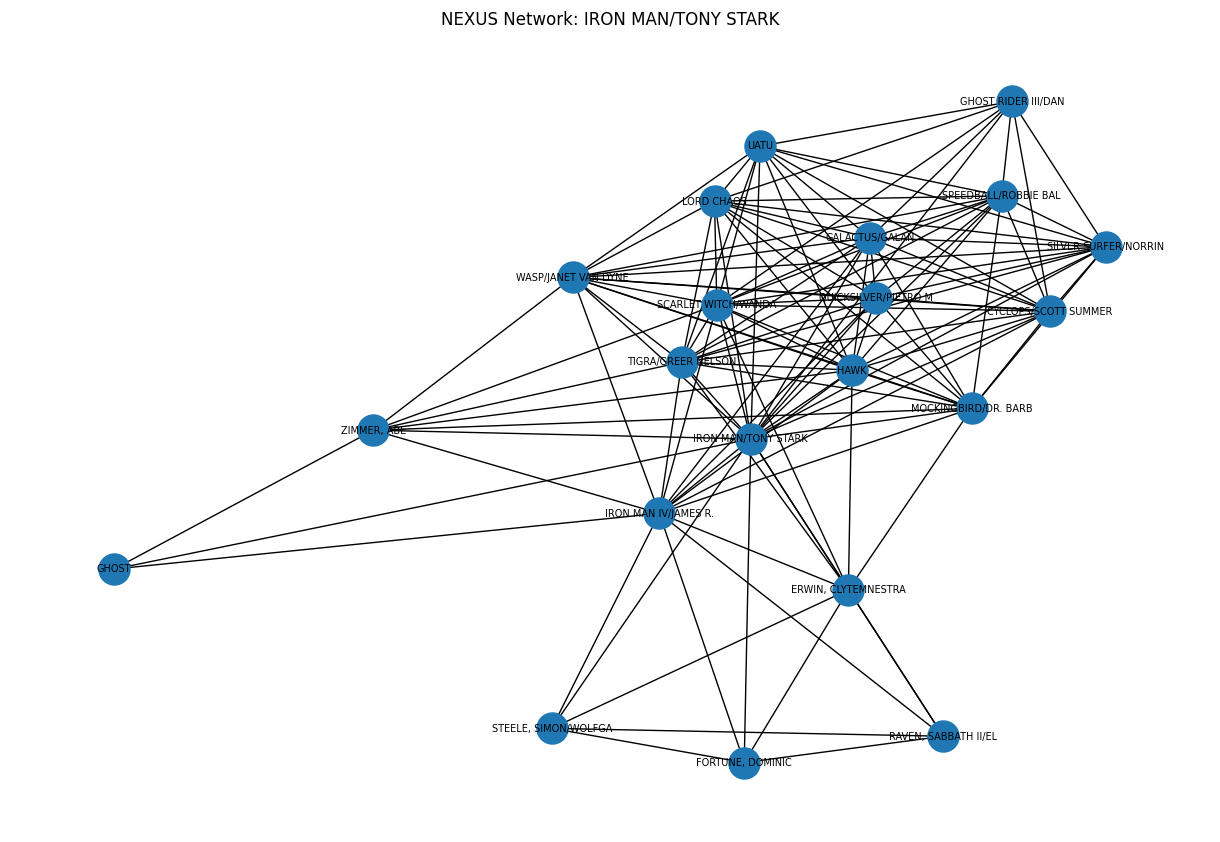

In [ ]:
nexus_visualize_character("Iron Man")

# Organizing events chronologically

In [ ]:
nexus_timeline = nexus_timeline.copy()

nexus_timeline["event_order"] = range(
    1, len(nexus_timeline) + 1
)

display(
    nexus_timeline[
        ["event_id", "event", "participants",
         "event_type", "confidence", "event_order"]
    ].head(10)
)

,event_id,event,participants,event_type,confidence,event_order
0,EVENT_0001,works with,[CAPTAIN AMERICA],narrative_event,0.5,1
1,EVENT_0002,transforms into,[HULK/DR. ROBERT BRUCE],narrative_event,0.5,2


In [ ]:
nexus_timeline = nexus_timeline.reset_index(drop=True)

display(nexus_timeline.head(10).to_string(index=False))

'  event_id           event            participants                        source_sentence      event_type  confidence  event_order\nEVENT_0001      works with       [CAPTAIN AMERICA]         He works with Captain America. narrative_event         0.5            1\nEVENT_0002 transforms into [HULK/DR. ROBERT BRUCE] Bruce Banner transforms into the Hulk. narrative_event         0.5            2'

In [ ]:
new_story = """
Iron Man fights Loki.
Captain America helps Iron Man.
Thor joins the Avengers.
"""

nexus_add_events(new_story)

display(nexus_timeline.tail(5))

,event_id,event,participants,source_sentence,event_type,confidence,event_order
0,EVENT_0001,works with,[CAPTAIN AMERICA],He works with Captain America.,narrative_event,0.5,1
1,EVENT_0002,transforms into,[HULK/DR. ROBERT BRUCE],Bruce Banner transforms into the Hulk.,narrative_event,0.5,2


In [ ]:
extracted_events = nexus_event_extraction("""
Iron Man fights Loki.
Captain America helps Iron Man.
Thor joins the Avengers.
""")

print(extracted_events)

                          sentence  action
0            Iron Man fights Loki.  fights
1  Captain America helps Iron Man.   helps
2         Thor joins the Avengers.   joins


In [ ]:
extracted_participants = nexus_event_participants("""
Iron Man fights Loki.
Captain America helps Iron Man.
Thor joins the Avengers.
""")

print(extracted_participants)

    event                            participants  \
0  fights             [IRON MAN/TONY STARK, LOKI]   
1   helps  [IRON MAN/TONY STARK, CAPTAIN AMERICA]   
2   joins                  [THOR/DR. DONALD BLAK]   

                   source_sentence  
0            Iron Man fights Loki.  
1  Captain America helps Iron Man.  
2         Thor joins the Avengers.  


In [ ]:
new_events = extracted_participants.copy()

new_events["event_id"] = [
    f"EVENT_{i:04d}"
    for i in range(
        len(nexus_timeline) + 1,
        len(nexus_timeline) + len(new_events) + 1
    )
]

new_events["event_type"] = "narrative_event"
new_events["confidence"] = 0.8
new_events["event_order"] = range(
    len(nexus_timeline) + 1,
    len(nexus_timeline) + len(new_events) + 1
)

nexus_timeline = pd.concat(
    [nexus_timeline, new_events],
    ignore_index=True
)

display(nexus_timeline.tail(5))

,event_id,event,participants,source_sentence,event_type,confidence,event_order
0,EVENT_0001,works with,[CAPTAIN AMERICA],He works with Captain America.,narrative_event,0.5,1
1,EVENT_0002,transforms into,[HULK/DR. ROBERT BRUCE],Bruce Banner transforms into the Hulk.,narrative_event,0.5,2
2,EVENT_0003,fights,"[IRON MAN/TONY STARK, LOKI]",Iron Man fights Loki.,narrative_event,0.8,3
3,EVENT_0004,helps,"[IRON MAN/TONY STARK, CAPTAIN AMERICA]",Captain America helps Iron Man.,narrative_event,0.8,4
4,EVENT_0005,joins,[THOR/DR. DONALD BLAK],Thor joins the Avengers.,narrative_event,0.8,5


In [ ]:
def nexus_search_events(character):
    character = nexus_resolve_character(character)

    matches = nexus_timeline[
        nexus_timeline["participants"].apply(
            lambda people: character in people
        )
    ]

    display(matches)

In [ ]:
nexus_search_events("Iron Man")

,event_id,event,participants,source_sentence,event_type,confidence,event_order
2,EVENT_0003,fights,"[IRON MAN/TONY STARK, LOKI]",Iron Man fights Loki.,narrative_event,0.8,3
3,EVENT_0004,helps,"[IRON MAN/TONY STARK, CAPTAIN AMERICA]",Captain America helps Iron Man.,narrative_event,0.8,4


In [ ]:
def nexus_continuity_check(events_df):
    issues = []

    for character in set(
        person
        for people in events_df["participants"]
        for person in people
    ):
        character_events = events_df[
            events_df["participants"].apply(
                lambda people: character in people
            )
        ]

        if len(character_events) > 1:
            issues.append({
                "character": character,
                "event_count": len(character_events),
                "events": character_events["source_sentence"].tolist(),
                "status": "Multiple events found — review chronology"
            })

    return pd.DataFrame(issues)

In [ ]:
display(nexus_continuity_check(nexus_timeline))

,character,event_count,events,status
0,CAPTAIN AMERICA,2,"[He works with Captain America., Captain Ameri...",Multiple events found — review chronology
1,IRON MAN/TONY STARK,2,"[Iron Man fights Loki., Captain America helps ...",Multiple events found — review chronology


In [ ]:
def nexus_query(name):
    print("\n=== CHARACTER PROFILE ===")
    nexus_rag_answer(name)

    print("\n=== RELATIONSHIPS ===")
    nexus_relationship_report(name)

    print("\n=== TIMELINE EVENTS ===")
    nexus_search_events(name)

In [ ]:
nexus_query("Iron Man")


=== CHARACTER PROFILE ===
NEXUS INTELLIGENCE REPORT
Query: Iron Man

Character: IRON MAN/TONY STARK
Type: character_profile
Information: IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
Evidence: Marvel character network dataset

=== RELATIONSHIPS ===

=== TIMELINE EVENTS ===


,event_id,event,participants,source_sentence,event_type,confidence,event_order
2,EVENT_0003,fights,"[IRON MAN/TONY STARK, LOKI]",Iron Man fights Loki.,narrative_event,0.8,3
3,EVENT_0004,helps,"[IRON MAN/TONY STARK, CAPTAIN AMERICA]",Captain America helps Iron Man.,narrative_event,0.8,4


In [ ]:
def nexus_relationship_report(name, top_k=5):
    canonical = nexus_resolve_character(name)

    results = nexus_shared_comics(
        canonical,
        top_k=top_k
    )

    print("Connections for:", canonical)
    display(results)

In [ ]:
nexus_query("Iron Man")


=== CHARACTER PROFILE ===
NEXUS INTELLIGENCE REPORT
Query: Iron Man

Character: IRON MAN/TONY STARK
Type: character_profile
Information: IRON MAN/TONY STARK has 1521 network connections, 1150.0 comic appearances, PageRank 0.004107976419617332, and belongs to community 4.
Evidence: Marvel character network dataset

=== RELATIONSHIPS ===
Connections for: IRON MAN/TONY STARK


,character,shared_comic_count,evidence_comics
0,CAPTAIN AMERICA,440,"[A '00, A '98, A '99, A 1, A 10]"
1,SCARLET WITCH/WANDA,375,"[A '00, A '98, A '99, A 1, A 10]"
2,THOR/DR. DONALD BLAK,339,"[A '98, A '99, A 1, A 1.5, A 10]"
3,VISION,335,"[A '98, A '99, A 10, A 100, A 101]"
4,WASP/JANET VAN DYNE,296,"[A 1, A 1.5, A 10, A 100, A 11]"



=== TIMELINE EVENTS ===


,event_id,event,participants,source_sentence,event_type,confidence,event_order
2,EVENT_0003,fights,"[IRON MAN/TONY STARK, LOKI]",Iron Man fights Loki.,narrative_event,0.8,3
3,EVENT_0004,helps,"[IRON MAN/TONY STARK, CAPTAIN AMERICA]",Captain America helps Iron Man.,narrative_event,0.8,4


In [ ]:
import os

os.makedirs("/content/NEXUS_outputs", exist_ok=True)

nexus_master_knowledge.to_csv(
    "/content/NEXUS_outputs/knowledge_base.csv",
    index=False
)

nexus_timeline.to_csv(
    "/content/NEXUS_outputs/timeline.csv",
    index=False
)

character_intelligence.to_csv(
    "/content/NEXUS_outputs/character_intelligence.csv",
    index=False
)

print("NEXUS datasets exported successfully.")

NEXUS datasets exported successfully.


In [ ]:
faiss.write_index(
    nexus_knowledge_index,
    "/content/NEXUS_outputs/nexus_faiss.index"
)

print("FAISS index saved successfully.")

FAISS index saved successfully.


In [ ]:
import json

nexus_config = {
    "project": "NEXUS",
    "version": "1.0",
    "knowledge_documents": len(nexus_master_knowledge),
    "embedding_dimensions": knowledge_embeddings.shape[1],
    "characters": len(character_intelligence),
    "timeline_events": len(nexus_timeline),
    "faiss_index": "nexus_faiss.index"
}

with open("/content/NEXUS_outputs/config.json", "w") as f:
    json.dump(nexus_config, f, indent=4)

print("NEXUS configuration saved.")

NEXUS configuration saved.


In [ ]:
import os
import numpy as np
import networkx as nx

output_dir = "/content/NEXUS_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save embeddings
np.save(
    f"{output_dir}/knowledge_embeddings.npy",
    knowledge_embeddings
)

# Save character network
nx.write_graphml(
    G_characters,
    f"{output_dir}/character_network.graphml"
)

print("Core NEXUS data saved.")

Core NEXUS data saved.


In [ ]:
import os
import numpy as np
import networkx as nx

output_dir = "/content/NEXUS_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save embeddings
np.save(
    f"{output_dir}/knowledge_embeddings.npy",
    knowledge_embeddings
)

# Save character network
nx.write_graphml(
    G_characters,
    f"{output_dir}/character_network.graphml"
)

print("Core NEXUS data saved.")

Core NEXUS data saved.


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/NEXUS_COMPLETE",
    "zip",
    "/content/NEXUS_outputs"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>